# 09 · Data validation and three-fold cross-validation

**Overview.** This notebook evaluates the quality, reproducibility, and interpretation of unsupervised clustering of cryo-EM particle images. It loads the saved CWF-based feature matrix from Notebook 03, checks particle identities against the CWF-to-original-MRC mapping from Notebook 02b, and applies the **frozen particle-level split** created in Notebook 01. The STAR metadata and CWF image stack have different row orders; fold assignments are therefore matched by particle identity, never by row number alone.

The analysis first evaluates the **original 96 radial features** using training-only feature scaling, PCA, and K-means in **three-fold cross-validation**. It compares cluster separation, PCA reconstruction, and stability across K-means random seeds. It then investigates whether the clusters are driven by overall image brightness, contrast, or alignment quality, and evaluates a **48-feature brightness-control representation** that emphasizes regional intensity differences.

After the training-fold comparisons, the notebook fits one final exploratory **48-feature, five-PC, three-cluster model** using the **51,396 development particles** (Folds 1–3). That saved model is then applied *without refitting* to the **5,711 held-out particles** (Fold 0). The notebook saves validation metrics, cluster assignments, model artifacts, and diagnostic figures. A later hyperparameter grid search is explicitly **post-test exploratory analysis**, not a new independent held-out evaluation.

**Scientific limitation.** These groups describe patterns in two-dimensional cryo-EM images; they do not by themselves establish distinct biological conformations. The split is particle-level rather than micrograph-level, and the upstream CWF processing may have included all particles.

**Prerequisites.** The frozen split from Notebook 01, the verified CWF particle mapping from Notebook 02b, and the saved feature checkpoint from Notebook 03 must be available. The original MRC image stack does not need to be loaded for the cross-validation calculations. Feature preprocessing must be learned on training particles only: do not apply a scaling transformation fitted to all particles before the split.


## 9.1 · Configuration and project discovery

Select **one** saved Section 3 feature source. `CHECKPOINT_DIRECTORY=None` uses the project's loader default (usually latest). Set a precise checkpoint to lock provenance. An optional metadata CSV can add `micrograph_id` for group-disjoint folds; it must contain `image_name` and `micrograph_id` columns. Do not assume that `image_name` alone is globally unique across datasets.

In [1]:
from pathlib import Path
import sys, json, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import adjusted_rand_score, silhouette_score
from threadpoolctl import threadpool_limits

# Detect the project root relative to the current working directory.

working_directory = Path.cwd().resolve()
project_root = next(
    (
        p for p in (working_directory, *working_directory.parents)
        if (p / "latent_methods.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Cannot find the ML4LS project root (latent_methods.py). "
        "Start Jupyter inside the repository or one of its subdirectories."
    )

# MODIFIED: Preserve Notebook 09's existing PROJECT_ROOT variable.
PROJECT_ROOT = project_root

# MODIFIED: Use the completed 96-feature radial baseline from Notebook 03.
FEATURE_SOURCE = "combined_cropped"

# MODIFIED: Point to the verified checkpoint from Section 3.10.
CHECKPOINT_DIRECTORY = (
    PROJECT_ROOT / "outputs" / "paired_1yn3a_7i"
)

# ADDED: Use the permanent split created before model fitting.
FROZEN_SPLIT_CSV = (
    PROJECT_ROOT / "outputs" / "validation"
    / "cv_3fold_with_unknown_test.csv"
)

# ORIGINAL: No micrograph IDs are available in the current STAR metadata.
METADATA_CSV = None
GROUP_COLUMN = "micrograph_id"
ALLOW_PARTICLE_LEVEL_FALLBACK = True

# ORIGINAL: Keep the agreed validation parameters for now.
N_SPLITS = 3
SPLIT_SEED = 42
N_PCS = 10
N_CLUSTERS = 6
KMEANS_SEEDS = (0, 1, 2, 3, 4)

# MODIFIED: Lower the feature-memory safety limit for the 8 GB Mac.
MAX_FEATURE_MEMORY_GB = 2.0

# ADDED: Limit parallel numerical operations on the 8 GB Mac.
# Reason: Avoid excessive CPU parallelism and temporary memory usage.
THREADS = 2

# ADDED: Limit silhouette evaluation to a reproducible sample.
# Reason: Silhouette calculations require pairwise distances,
# which become expensive for thousands of particles.
MAX_SILHOUETTE_SAMPLE = 1000
OUTPUT_DIRECTORY = None  # default: project/outputs/validation_09/<timestamp>

# MODIFIED: Check the actual saved feature-scaling configuration.
# Reason: Our radial checkpoint was created with scaling="none".
# Reject a globally scaled checkpoint rather than bypassing the safety check.
if FEATURE_SOURCE == "combined_cropped":
    checkpoint_settings = json.loads(
        (CHECKPOINT_DIRECTORY / "settings.json").read_text()
    )

    assert checkpoint_settings["feature_scaling"] == "none", (
        "This checkpoint uses full-dataset scaling. "
        "Do not use it for cross-validation."
    )

    # ADDED: Ensure this is our intended 96-feature radial baseline.
    assert checkpoint_settings["feature_order"] == [
        "original_intensity_sum",
        "original_positive_pixel_count",
        "derivative_intensity_sum",
        "derivative_positive_pixel_count",
    ]

    print("Feature checkpoint scaling: none (verified)")
if N_SPLITS != 3:
    raise ValueError('This notebook is designed for three-fold CV.')
if not KMEANS_SEEDS:
    raise ValueError('Provide at least one K-means seed.')

# MODIFIED: The project root was already detected above.
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
# ORIGINAL: The notebook added LatentSpace to Python's import path.
# MODIFIED: Also include the project root, where helper modules may live.
for module_dir in (PROJECT_ROOT, PROJECT_ROOT / "LatentSpace"):
    if module_dir.is_dir() and str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))

# ORIGINAL: Import the paired dataset loader.
# MODIFIED: Restore the import now that Notebook 03 is complete.
from particle_paired import load_paired_dataset
SOURCE_ROOT = PROJECT_ROOT / 'outputs'
run_tag = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT = Path(OUTPUT_DIRECTORY).expanduser().resolve() if OUTPUT_DIRECTORY else SOURCE_ROOT / 'validation_09' / run_tag
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'figures').mkdir(exist_ok=True)
print('Project:', PROJECT_ROOT)
print('Outputs:', OUT)


Feature checkpoint scaling: none (verified)
Project: /Users/kr/ml4ls
Outputs: /Users/kr/ml4ls/outputs/validation_09/20261113T040853Z


In [12]:
# ADDED: Load the frozen validation assignments.
# Reason: Use the same train, validation, and test partitions
# throughout the pipeline instead of generating new random folds.

FROZEN_SPLIT_CSV = (
    PROJECT_ROOT / "outputs" / "validation"
    / "cv_3fold_with_unknown_test.csv"
)

# ADDED: Read the permanent particle-level assignments.
cv_manifest = pd.read_csv(FROZEN_SPLIT_CSV)

# ADDED: Check all expected columns are present.
required_columns = {
    "particle_id",
    "star_row",
    "stack_index_1based",
    "split",
    "cv_fold",
}
assert required_columns.issubset(cv_manifest.columns)

# ADDED: Check that every particle occurs exactly once.
assert len(cv_manifest) == 57107
assert cv_manifest["particle_id"].is_unique
assert cv_manifest["star_row"].is_unique
assert cv_manifest["stack_index_1based"].is_unique

# ADDED: Verify that the original stack is fully represented.
assert np.array_equal(
    np.sort(cv_manifest["stack_index_1based"].to_numpy()),
    np.arange(1, 57108),
)

# ADDED: Check the expected group sizes.
expected_counts = {0: 5711, 1: 17132, 2: 17132, 3: 17132}

actual_counts = (
    cv_manifest["cv_fold"]
    .value_counts()
    .sort_index()
    .to_dict()
)

assert actual_counts == expected_counts

# ADDED: Establish permanent development and test masks.
development_mask = cv_manifest["cv_fold"].isin([1, 2, 3])
test_mask = cv_manifest["cv_fold"].eq(0)

assert int(development_mask.sum()) == 51396
assert int(test_mask.sum()) == 5711
assert not np.any(development_mask & test_mask)

print("Frozen validation split: VERIFIED")
print("Total particles:", len(cv_manifest))
print("Development particles:", int(development_mask.sum()))
print("Held-out test particles:", int(test_mask.sum()))
print("Fold counts:", actual_counts)

Frozen validation split: VERIFIED
Total particles: 57107
Development particles: 51396
Held-out test particles: 5711
Fold counts: {0: 5711, 1: 17132, 2: 17132, 3: 17132}


In [13]:
# ADDED: Load the verified CWF-to-particle mapping.
# Reason: Match validation assignments to CWF image rows,
# not STAR row positions.

mapping_path = (
    PROJECT_ROOT / "outputs" / "validation"
    / "cwf_particle_mapping.csv"
)

# ADDED: Load the CWF mapping saved in Notebook 02b.
cwf_mapping = pd.read_csv(mapping_path)

assert len(cwf_mapping) == 57107

assert np.array_equal(
    cwf_mapping["cwf_row_0based"].to_numpy(),
    np.arange(57107),
)

# ADDED: Compare each particle's frozen CV assignment
# using its unique particle ID.
expected = cv_manifest.set_index("particle_id")["cv_fold"]

mapped_folds = cwf_mapping["particle_id"].map(expected)

assert mapped_folds.notna().all()

assert np.array_equal(
    mapped_folds.to_numpy(),
    cwf_mapping["cv_fold"].to_numpy(),
)

# ADDED: Create masks in CWF image order.
cwf_development_mask = cwf_mapping["cv_fold"].isin([1, 2, 3]).to_numpy()
cwf_test_mask = cwf_mapping["cv_fold"].eq(0).to_numpy()

# ADDED: Confirm no overlap between the groups.
assert int(cwf_development_mask.sum()) == 51396
assert int(cwf_test_mask.sum()) == 5711
assert not np.any(cwf_development_mask & cwf_test_mask)

print("CWF-to-validation mapping: VERIFIED")
print("CWF development particles:", int(cwf_development_mask.sum()))
print("CWF held-out test particles:", int(cwf_test_mask.sum()))
print("First five CWF fold assignments:",
      cwf_mapping["cv_fold"].head().tolist())

CWF-to-validation mapping: VERIFIED
CWF development particles: 51396
CWF held-out test particles: 5711
First five CWF fold assignments: [2, 2, 1, 2, 3]


## 9.2 · Load source and audit integrity

Load a **saved paired checkpoint**, preserving its `image_names` order. We reject missing or duplicate IDs, non-finite features, and inconsistent rows. Constant features are permitted; PCA handles centering. `empty_masks` (if present) is exported for inspection. Large matrices can consume substantial RAM.

In [14]:
bundle = load_paired_dataset(SOURCE_ROOT, FEATURE_SOURCE, CHECKPOINT_DIRECTORY)
checkpoint_path = Path(bundle['directory']).resolve()
names = np.asarray(bundle['image_names']).astype(str)
raw = np.asarray(bundle['vectors'])
if raw.ndim < 2:
    raise ValueError(f'Expected a feature matrix, got {raw.shape}')
if raw.ndim > 2:
    raw = raw.reshape(len(raw), -1)
if raw.shape[0] != len(names):
    raise ValueError('Image IDs and feature rows do not match')
if len(names) < N_SPLITS * 2:
    raise ValueError('Not enough particles for the requested folds')
if pd.Series(names).duplicated().any():
    duplicate_examples = pd.Series(names)[pd.Series(names).duplicated()].head(5).tolist()
    raise ValueError(f'Duplicate image IDs; resolve provenance before splitting: {duplicate_examples}')
if pd.Series(names).str.len().eq(0).any():
    raise ValueError('Blank image IDs')
est_gb = raw.size * 4 / 1024**3
if est_gb > MAX_FEATURE_MEMORY_GB:
    raise MemoryError(f'Float32 feature matrix requires approximately {est_gb:.2f} GiB; raise memory guard only after checking RAM or select a smaller feature block')
X = np.asarray(raw, dtype=np.float32)
if not np.isfinite(X).all():
    raise ValueError('Feature matrix contains NaN/Inf; fix Section 3 outputs before CV')
if X.shape[1] < 2:
    raise ValueError('Need at least two feature columns')
manifest = pd.DataFrame({'image_name': names, 'source_row_0based': np.arange(len(names)), 'feature_source': FEATURE_SOURCE})
if 'empty_masks' in bundle and len(bundle['empty_masks']) == len(names):
    manifest['empty_mask'] = np.asarray(bundle['empty_masks']).astype(bool)

quality = pd.DataFrame([{
    'n_particles': len(names), 'n_features': X.shape[1], 'estimated_float32_GiB': est_gb,
    'duplicate_ids': int(pd.Series(names).duplicated().sum()),
    'nonfinite_values': int((~np.isfinite(X)).sum()),
    'zero_variance_features': int(np.count_nonzero(X.var(axis=0, dtype=np.float64) == 0)),
    'zero_norm_particles': int(np.count_nonzero(np.linalg.norm(X, axis=1) == 0)),
    'source_checkpoint': str(checkpoint_path), 'feature_source': FEATURE_SOURCE,
}])
quality.to_csv(OUT / 'data_quality_report.csv', index=False)
display(quality.T.rename(columns={0:'value'}))


,value
n_particles,57107
n_features,96
estimated_float32_GiB,0.020423
duplicate_ids,0
nonfinite_values,0
zero_variance_features,0
zero_norm_particles,0
source_checkpoint,/Users/kr/ml4ls/outputs/paired_1yn3a_7i
feature_source,combined_cropped


In [15]:
# Verify feature rows against the frozen CWF particle mapping.
# Reason: Prevent incorrect CV assignments caused by differing
# STAR and CWF particle orders.

# Compare all particle IDs in feature-matrix order.
feature_ids = pd.Series(names, dtype="string")
mapping_ids = cwf_mapping["particle_id"].astype("string")

assert len(feature_ids) == len(mapping_ids) == X.shape[0]

# Require an exact row-by-row match.
assert np.array_equal(
    feature_ids.to_numpy(),
    mapping_ids.to_numpy(),
), "Feature rows do not match the CWF particle mapping!"

# Record fold assignments in feature-matrix order.
feature_folds = cwf_mapping["cv_fold"].to_numpy(dtype=int)

assert np.array_equal(
    feature_folds[:5],
    np.array([2, 2, 1, 2, 3]),
)

assert np.count_nonzero(feature_folds == 0) == 5711
assert np.count_nonzero(np.isin(feature_folds, [1, 2, 3])) == 51396

print("Feature-to-CWF particle order: VERIFIED")
print("Feature rows:", X.shape[0])
print("Feature columns:", X.shape[1])
print("First five folds:", feature_folds[:5].tolist())
print("Held-out test particles:", np.count_nonzero(feature_folds == 0))

Feature-to-CWF particle order: VERIFIED
Feature rows: 57107
Feature columns: 96
First five folds: [2, 2, 1, 2, 3]
Held-out test particles: 5711


In [8]:
print("Particle 5:",feature_folds[4])
print("Particle 6:",feature_folds[6])

Particle 5: 3
Particle 6: 2


## 9.3 · Attach acquisition groups and create three folds

**Preferred:** join a metadata CSV by exact `image_name`; group using `micrograph_id` (or a stronger acquisition identifier). If metadata are missing, optionally fall back to seeded particle-level K-fold and mark the results as **not acquisition-independent**.

This notebook uses **all particles** in the three validation folds (roughly 16.7k each for 50k particles). There is no separate test set. Exact sizes depend on grouping.

In [16]:

# ORIGINAL: This cell used KFold or GroupKFold to create new splits.
# MODIFIED: Use the verified, frozen particle assignments instead.
# Reason: Preserve the original three CV folds and exclude
# all 5,711 held-out test particles from model development.

# Ensure that the feature matrix and particle manifest
# contain the same number of rows.
assert len(manifest) == len(X)

# Require unique particle identifiers.
assert "image_name" in manifest.columns
assert manifest["image_name"].is_unique

# Use the frozen assignments, matched by particle ID.
# Never assume that STAR order equals CWF or feature order.
frozen_folds = cv_manifest[
    ["particle_id", "cv_fold"]
].rename(columns={"particle_id": "image_name"})

# Match each feature row to its permanent fold.
matched_folds = manifest["image_name"].map(
    frozen_folds.set_index("image_name")["cv_fold"]
)

# Stop if any feature lacks a frozen assignment.
if matched_folds.isna().any():
    raise ValueError(
        f"{int(matched_folds.isna().sum())} feature rows "
        "have no matching frozen fold."
    )

# Assign frozen folds instead of generating new ones.
manifest["cv_fold"] = matched_folds.to_numpy(dtype=int)

# Verify that the full dataset is present.
expected_counts = {0: 5711, 1: 17132, 2: 17132, 3: 17132}
actual_counts = manifest["cv_fold"].value_counts().sort_index().to_dict()
assert actual_counts == expected_counts

# Create three train/validation pairs.
# Fold 0 is excluded from every training and validation set.
fold_pairs = []

for validation_fold in (1, 2, 3):
    train_idx = np.flatnonzero(
        manifest["cv_fold"].isin(
            [f for f in (1, 2, 3) if f != validation_fold]
        ).to_numpy()
    )

    val_idx = np.flatnonzero(
        manifest["cv_fold"].eq(validation_fold).to_numpy()
    )

    # ADDED: Validate partition sizes and disjointness.
    assert len(train_idx) == 34264
    assert len(val_idx) == 17132
    assert not np.intersect1d(train_idx, val_idx).size

    fold_pairs.append((train_idx, val_idx))

#Identify the held-out test rows without using them.
test_idx = np.flatnonzero(
    manifest["cv_fold"].eq(0).to_numpy()
)

assert len(test_idx) == 5711

# Record the actual split method.
split_method = "Frozen particle-level 3-fold CV + held-out test"

# Preserve a copy of the verified assignments.
manifest.to_csv(OUT / "cv_splits.csv", index=False)

print("Split method:", split_method)
print("Cross-validation folds:", len(fold_pairs))
print("Held-out test particles:", len(test_idx))
display(
    manifest.groupby("cv_fold")
    .size()
    .rename("particles")
    .to_frame()
)



Split method: Frozen particle-level 3-fold CV + held-out test
Cross-validation folds: 3
Held-out test particles: 5711


,particles
cv_fold,
0,5711
1,17132
2,17132
3,17132


## 9.4 · Train-only PCA + K-means cross-validation

For each fold: fit PCA on training rows, project validation rows, fit K-means in training PC space, then assign validation rows to the **training** centroids. We assess held-out PCA reconstruction error and centroid-based cluster separation. Repeated K-means seeds provide assignment stability (ARI computed on the **same validation particles**). K-means is invariant to cluster label numbers, so ARI is appropriate here.

**No supervised labels or true conformations are assumed.** Scores describe the chosen 2D representation, not verified 3D structural states.

In [17]:
# ADDED: Check computational settings before PCA and K-means.

for name in ("THREADS", "MAX_SILHOUETTE_SAMPLE"):
    if name in globals():
        print(f"{name} = {globals()[name]}")
    else:
        print(f"{name} = NOT DEFINED")

print("Feature matrix:", X.shape)
print("CV folds:", len(fold_pairs))
print("PCA components:", N_PCS)
print("K-means clusters:", N_CLUSTERS)

THREADS = 2
MAX_SILHOUETTE_SAMPLE = 1000
Feature matrix: (57107, 96)
CV folds: 3
PCA components: 10
K-means clusters: 6


In [18]:

# ============================================================
# Notebook 09 — PCA and K-means cross-validation
# MODIFIED: Complete, corrected replacement for the original CV cell.
# Reason: Fit scaling, PCA, and K-means on training particles only.
# The 5,711 held-out test particles are never used for model fitting.
# ============================================================

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances_argmin_min
if N_PCS < 2 or N_CLUSTERS < 2:
    raise ValueError("N_PCS and N_CLUSTERS must each be at least 2")

# Verify the expected frozen CV partitions before fitting.
assert len(fold_pairs) == 3
assert X.shape == (57107, 96)

for validation_fold, (train_idx, val_idx) in enumerate(fold_pairs, start=1):
    assert len(train_idx) == 34264
    assert len(val_idx) == 17132

    assert np.all(
        manifest.iloc[train_idx]["cv_fold"].to_numpy() != 0
    )

    assert np.all(
        manifest.iloc[val_idx]["cv_fold"].to_numpy() == validation_fold
    )

cv_records = []
seed_records = []
stability_records = []
predictions = []
variance_records = []

models = {}

# ============================================================
# Run three frozen cross-validation folds
# ============================================================

for fold, (train_idx, val_idx) in enumerate(fold_pairs, start=1):

    train = X[train_idx]
    val = X[val_idx]

 
    scaler = StandardScaler()
    train_scaled = scaler.fit_transform(train)


    val_scaled = scaler.transform(val)

    # Choose the number of PCA components.
    n_pc = min(N_PCS, len(train_scaled) - 1, train_scaled.shape[1])

    if n_pc < 2 or len(train_scaled) <= N_CLUSTERS:
        raise ValueError("Too few training rows/features for PCA or K-means")

    with threadpool_limits(limits=THREADS):

        # Fit PCA on scaled training particles only.
        pca = PCA(
            n_components=n_pc,
            svd_solver="randomized",
            random_state=SPLIT_SEED,
        )

        train_z = pca.fit_transform(train_scaled)

        # Transform validation particles without refitting.
        val_z = pca.transform(val_scaled)

        # Calculate validation reconstruction error.
        restored = pca.inverse_transform(val_z)

        mse = float(
            np.mean((val_scaled - restored) ** 2, dtype=np.float64)
        )

        # Run K-means using the configured random seeds.
        fold_labels = []
        fold_models = []

        # Use one reproducible validation sample per fold.
        sample_size = min(MAX_SILHOUETTE_SAMPLE, len(val_z))
        rng = np.random.default_rng(SPLIT_SEED)

        sample_idx = rng.choice(
            len(val_z),
            size=sample_size,
            replace=False,
        )

        sample_z = val_z[sample_idx]

        for seed in KMEANS_SEEDS:

            # Fit K-means on PCA training coordinates.
            km = KMeans(
                n_clusters=N_CLUSTERS,
                random_state=int(seed),
                n_init=20,
            )

            km.fit(train_z)

            # Predict validation cluster assignments.
            val_labels = km.predict(val_z)

            fold_labels.append(val_labels)
            fold_models.append(km)

            # Compute silhouette on sampled validation data.
            # Reason: Avoid very large pairwise-distance matrices.
            sil = float("nan")
            sample_labels = val_labels[sample_idx]

            n_sample_clusters = len(np.unique(sample_labels))

            if 2 <= n_sample_clusters < len(sample_labels):
                sil = float(
                    silhouette_score(sample_z, sample_labels)
                )

            # Record metrics for this K-means seed.
            seed_records.append({
                "fold": fold,
                "seed": int(seed),
                "silhouette_val": sil,
                "train_inertia": float(km.inertia_),
                "n_val_clusters": int(len(np.unique(val_labels))),
            })

        # Use the first seed for saved validation predictions.
        base_labels = fold_labels[0]

        _, nearest_dist = pairwise_distances_argmin_min(
            val_z,
            fold_models[0].cluster_centers_,
        )

        for i, j in enumerate(val_idx):
            predictions.append({
                "image_name": names[j],
                "cv_fold": fold,
                "source_row_0based": int(j),
                "cluster": int(base_labels[i]) + 1,
                "distance_to_centroid": float(nearest_dist[i]),
            })

        # Compare K-means assignments across random seeds.
        for i in range(len(fold_labels)):
            for j in range(i + 1, len(fold_labels)):

                stability_records.append({
                    "fold": fold,
                    "seed_a": int(KMEANS_SEEDS[i]),
                    "seed_b": int(KMEANS_SEEDS[j]),
                    "ARI_same_validation_images": float(
                        adjusted_rand_score(
                            fold_labels[i],
                            fold_labels[j],
                        )
                    ),
                })

        # Record explained variance for each PCA component.
        for pc, ratio in enumerate(
            pca.explained_variance_ratio_,
            start=1,
        ):
            variance_records.append({
                "fold": fold,
                "PC": pc,
                "explained_variance_ratio": float(ratio),
            })

        # Save summary metrics for each CV fold.
        cv_records.append({
            "fold": fold,
            "n_train": len(train_idx),
            "n_validation": len(val_idx),
            "n_pcs": n_pc,
            "n_clusters_requested": N_CLUSTERS,
            "train_explained_variance_sum": float(
                pca.explained_variance_ratio_.sum()
            ),
            "validation_pca_reconstruction_mse": mse,
            "validation_silhouette_seed0": (
                seed_records[-len(KMEANS_SEEDS)]["silhouette_val"]
            ),
        })

        # Save the fitted preprocessing and clustering models.
        models[fold] = {
            "scaler": scaler,
            "pca": pca,
            "kmeans": fold_models[0],
        }

    print(
        f"Fold {fold}: "
        f"train={len(train_idx):,}, "
        f"validate={len(val_idx):,}, "
        f"PCA variance={pca.explained_variance_ratio_.sum():.1%}, "
        f"validation MSE={mse:.4g}"
    )

# ============================================================
# Verify that the held-out test particles were excluded
# ============================================================

predicted_ids = pd.Series(
    [record["image_name"] for record in predictions],
    dtype=str,
)

assert len(predicted_ids) == 51396
assert predicted_ids.is_unique

development_ids = set(
    manifest.loc[
        manifest["cv_fold"].isin([1, 2, 3]),
        "image_name",
    ].astype(str)
)

test_ids = set(
    manifest.loc[
        manifest["cv_fold"].eq(0),
        "image_name",
    ].astype(str)
)


assert set(predicted_ids) == development_ids

assert set(predicted_ids).isdisjoint(test_ids)

# Verify train/validation partitions.
for fold, (train_idx, val_idx) in enumerate(fold_pairs, start=1):

    assert len(train_idx) == 34264
    assert len(val_idx) == 17132

    assert np.all(
        manifest.iloc[train_idx]["cv_fold"].to_numpy() != 0
    )

    assert np.all(
        manifest.iloc[val_idx]["cv_fold"].to_numpy() == fold
    )

print("Cross-validation leakage checks: PASSED")
print("Development predictions:", len(predicted_ids))
print("Held-out test predictions: 0")

# ============================================================
# Save metrics and display results
# ============================================================

cv_metrics = pd.DataFrame(cv_records)
seed_metrics = pd.DataFrame(seed_records)
stability_metrics = pd.DataFrame(stability_records)

pred_table = pd.DataFrame(predictions).merge(
    manifest.drop(
        columns=[
            "feature_source",
            "source_row_0based",
            "cv_fold",
        ]
    ),
    on="image_name",
    how="left",
    validate="one_to_one",
)

variance_table = pd.DataFrame(variance_records)

cv_metrics.to_csv(OUT / "pca_cv_metrics.csv", index=False)
seed_metrics.to_csv(OUT / "kmeans_cv_metrics.csv", index=False)
stability_metrics.to_csv(OUT / "cluster_stability.csv", index=False)

pred_table.to_csv(
    OUT / "out_of_fold_cluster_assignments.csv",
    index=False,
)

variance_table.to_csv(
    OUT / "pca_variance_by_fold.csv",
    index=False,
)

display(cv_metrics)

display(
    seed_metrics.groupby("fold")[["silhouette_val"]].agg(
        ["mean", "std"]
    )
)
if len(stability_metrics):
    display(
        stability_metrics.groupby("fold")[
            "ARI_same_validation_images"
        ].agg(["mean", "min", "max"])
    )


Fold 1: train=34,264, validate=17,132, PCA variance=76.0%, validation MSE=0.239
Fold 2: train=34,264, validate=17,132, PCA variance=75.8%, validation MSE=0.2451
Fold 3: train=34,264, validate=17,132, PCA variance=75.8%, validation MSE=0.2413
Cross-validation leakage checks: PASSED
Development predictions: 51396
Held-out test predictions: 0


,fold,n_train,n_validation,n_pcs,n_clusters_requested,train_explained_variance_sum,validation_pca_reconstruction_mse,validation_silhouette_seed0
0,1,34264,17132,10,6,0.759811,0.238981,0.182297
1,2,34264,17132,10,6,0.758499,0.245144,0.176532
2,3,34264,17132,10,6,0.758286,0.241330,0.182703


silhouette_val          
               mean       std
fold                         
1          0.181362  0.001091
2          0.176731  0.000291
3          0.182856  0.000318

,mean,min,max
fold,,,
1,0.978871,0.959541,0.999741
2,0.984932,0.971533,0.998314
3,0.994535,0.987588,0.999944


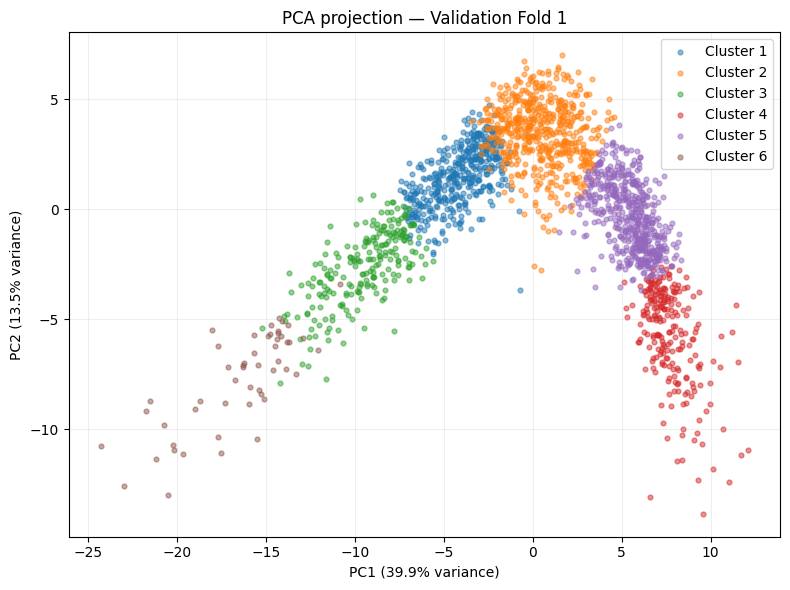

In [19]:
#Visualize PCA results for validation Fold 1.

import numpy as np
import matplotlib.pyplot as plt

# Retrieve the fitted models for Fold 1.
fold = 1
scaler = models[fold]["scaler"]
pca = models[fold]["pca"]
km = models[fold]["kmeans"]

val_idx = fold_pairs[0][1]
val = X[val_idx]

val_scaled = scaler.transform(val)
val_z = pca.transform(val_scaled)

Predict clusters using the already fitted K-means model.
cluster_labels = km.predict(val_z) + 1

rng = np.random.default_rng(42)
sample_idx = rng.choice(
    len(val_z),
    size=min(2000, len(val_z)),
    replace=False
)

plt.figure(figsize=(8, 6))

for cluster in np.unique(cluster_labels):
    idx = sample_idx[cluster_labels[sample_idx] == cluster]

    plt.scatter(
        val_z[idx, 0],
        val_z[idx, 1],
        s=12,
        alpha=0.5,
        label=f"Cluster {cluster}"
    )

variance = pca.explained_variance_ratio_ * 100

plt.xlabel(f"PC1 ({variance[0]:.1f}% variance)")
plt.ylabel(f"PC2 ({variance[1]:.1f}% variance)")
plt.title("PCA projection — Validation Fold 1")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

In [20]:
# Examine validation cluster sizes across the three CV folds.
# Reason: Detect very small or imbalanced clusters before
# interpreting the unsupervised grouping.
# 

cluster_counts = (
    pred_table
    .groupby(["cv_fold", "cluster"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=[1, 2, 3], columns=range(1, N_CLUSTERS + 1), fill_value=0)
)

cluster_percent = (
    cluster_counts
    .div(cluster_counts.sum(axis=1), axis=0)
    * 100
)

print("Validation particles per cluster:")
display(cluster_counts)

print("Percentage of validation particles per cluster:")
display(cluster_percent.round(2))

# Ensure every development particle appears exactly once.
assert cluster_counts.to_numpy().sum() == 51396
assert (cluster_counts.sum(axis=1) == 17132).all()

print("Cluster-size verification: PASSED")

Validation particles per cluster:


cluster,1,2,3,4,5,6
cv_fold,,,,,,
1,3678,4742,1997,2143,4162,410
2,4776,2220,1974,4042,492,3628
3,3967,537,2168,2169,3588,4703


Percentage of validation particles per cluster:


cluster,1,2,3,4,5,6
cv_fold,,,,,,
1,21.47,27.68,11.66,12.51,24.29,2.39
2,27.88,12.96,11.52,23.59,2.87,21.18
3,23.16,3.13,12.65,12.66,20.94,27.45


Cluster-size verification: PASSED


## 9.5 · Diagnostic plots and cautions

These figures summarize cross-validation **within each fold**. Cluster labels from independently trained folds are arbitrary and must **not** be interpreted as matched biological states. For comparable cluster average images, rerun Section 8 on a selected single final model or explicitly match clusters using shared features before comparing.

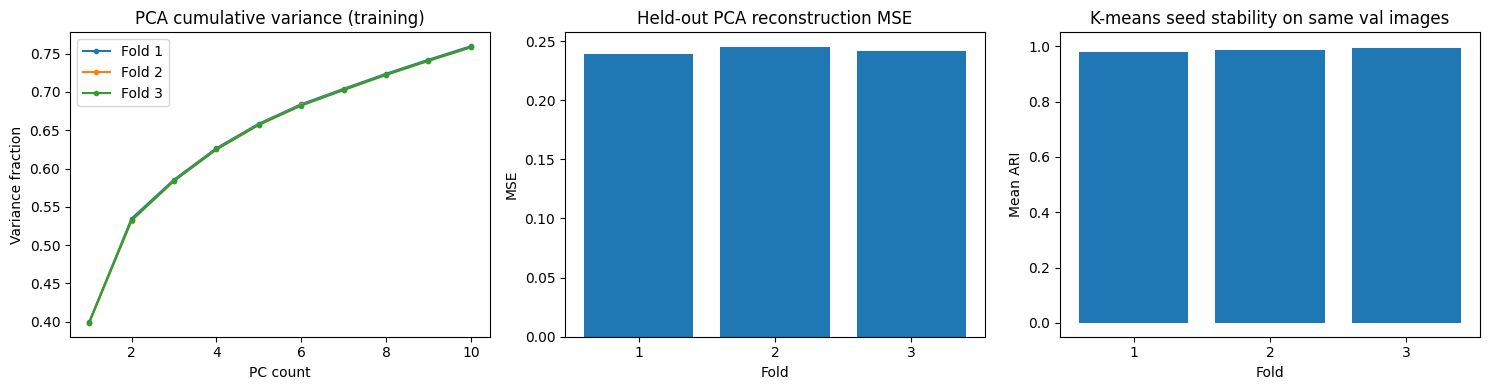

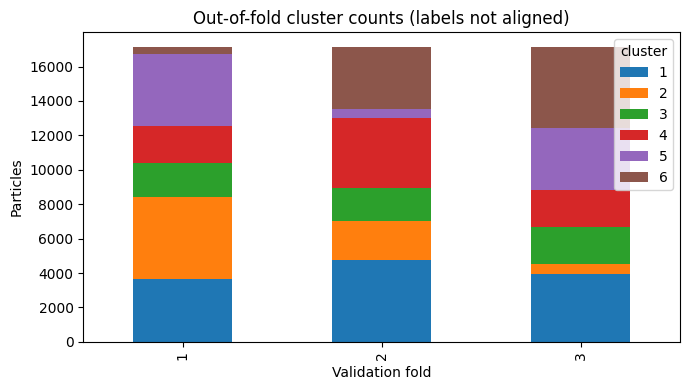

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for fold, sub in variance_table.groupby('fold'):
    axes[0].plot(sub['PC'],sub['explained_variance_ratio'].cumsum(),marker='.',label=f'Fold {fold}')
axes[0].set(title='PCA cumulative variance (training)',xlabel='PC count',ylabel='Variance fraction')
axes[0].legend()
axes[1].bar(cv_metrics['fold'].astype(str), cv_metrics['validation_pca_reconstruction_mse'])
axes[1].set(title='Held-out PCA reconstruction MSE',xlabel='Fold',ylabel='MSE')
ari_by_fold = stability_metrics.groupby('fold')['ARI_same_validation_images'].mean() if len(stability_metrics) else pd.Series(dtype=float)
axes[2].bar([str(x) for x in ari_by_fold.index],ari_by_fold.values)
axes[2].set(title='K-means seed stability on same val images',xlabel='Fold',ylabel='Mean ARI',ylim=(-0.05,1.05))
fig.tight_layout()
fig.savefig(OUT/'figures'/'validation_overview.png',dpi=160)
plt.show()

fig,ax=plt.subplots(figsize=(7,4))
pred_table.groupby(['cv_fold','cluster']).size().unstack(fill_value=0).plot(kind='bar',stacked=True,ax=ax)
ax.set(title='Out-of-fold cluster counts (labels not aligned)',xlabel='Validation fold',ylabel='Particles')
fig.tight_layout();fig.savefig(OUT/'figures'/'cluster_counts_by_fold.png',dpi=160)
plt.show()


## 9.6 · Save summary, verify outputs, and plan integration

The CSV files retain exact image IDs, checkpoint path in the summary, training/validation split labels, and out-of-fold assignments. You can join a future dataset by a **globally unique particle ID** (if names repeat across imports, first add a dataset prefix). To integrate new particles, keep this fold manifest fixed; don't regenerate it when comparing models.

**Interpretation limits**: a high silhouette or stable ARI does not establish protein conformations; clusters may represent orientations or acquisition effects. No DBSCAN/HDBSCAN/ICA cross-validation is performed here. A complete leakage-free multi-block `combined_cropped` CV requires a separate fold-aware combination stage.

In [22]:

#Verify the saved feature checkpoint was not globally scaled.
feature_scaling = bundle["settings"].get("feature_scaling")

assert feature_scaling == "none", (
    "Expected the unscaled 96-feature radial checkpoint."
)

#Confirm the held-out test set has no predictions.
assert len(pred_table) == 51396
assert pred_table["image_name"].is_unique
assert not pred_table["image_name"].isin(test_ids).any()
assert set(pred_table["cv_fold"].unique()) == {1, 2, 3}

summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "feature_source": FEATURE_SOURCE,
    "source_checkpoint": str(checkpoint_path),
    "feature_scaling": feature_scaling,
    "cv_scaling": "StandardScaler fitted on each training fold only",
    "n_particles": int(len(names)),
    "n_features": int(X.shape[1]),
    "n_development_particles": 51396,
    "n_held_out_test_particles": 5711,
    "n_out_of_fold_predictions": int(len(pred_table)),
    "split_method": split_method,

   
    "group_column": None,

    "n_splits": int(N_SPLITS),
    "split_seed": int(SPLIT_SEED),
    "n_pcs_requested": int(N_PCS),
    "n_clusters_requested": int(N_CLUSTERS),
    "kmeans_seeds": [int(s) for s in KMEANS_SEEDS],

   
    "uses_precombined_global_scaled_features": False,

   
    "caveat": (
        "Single-protein 2D particle-level cluster validation; "
        "does not establish 3D conformations. "
        "Micrograph-level independence was not verified. "
        "Upstream CWF preprocessing independence was not established."
    ),
}


(OUT / "validation_summary.json").write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

expected = [
    "cv_splits.csv",
    "data_quality_report.csv",
    "pca_cv_metrics.csv",
    "kmeans_cv_metrics.csv",
    "cluster_stability.csv",
    "out_of_fold_cluster_assignments.csv",
    "pca_variance_by_fold.csv",
    "validation_summary.json",
]

assert all((OUT / filename).is_file() for filename in expected)
assert summary["n_particles"] == 57107
assert summary["n_development_particles"] == 51396
assert summary["n_held_out_test_particles"] == 5711
assert summary["n_out_of_fold_predictions"] == 51396

print("Final validation report: SAVED")
print("Development predictions:", len(pred_table))
print("Held-out test predictions: 0")
print("Feature scaling:", feature_scaling)
print("Saved report folder:", OUT)
print("Files:", *expected, sep="\n  - ")

Final validation report: SAVED
Development predictions: 51396
Held-out test predictions: 0
Feature scaling: none
Saved report folder: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z
Files:
  - cv_splits.csv
  - data_quality_report.csv
  - pca_cv_metrics.csv
  - kmeans_cv_metrics.csv
  - cluster_stability.csv
  - out_of_fold_cluster_assignments.csv
  - pca_variance_by_fold.csv
  - validation_summary.json


In [18]:
#Identify which validation report files are missing.
# Reason: Diagnose the final assertion without rerunning PCA/K-means.

print("Report directory:", OUT)
print()

for filename in expected:
    file_path = OUT / filename

    if file_path.is_file():
        print("FOUND:  ", filename)
    else:
        print("MISSING:", filename)

print()
print("Files currently in the report directory:")

for path in sorted(OUT.iterdir()):
    print(" -", path.name)

Report directory: /Users/kr/ml4ls/outputs/validation_09/20261109T175733Z

MISSING: cv_splits.csv
MISSING: data_quality_report.csv
FOUND:   pca_cv_metrics.csv
FOUND:   kmeans_cv_metrics.csv
FOUND:   cluster_stability.csv
FOUND:   out_of_fold_cluster_assignments.csv
FOUND:   pca_variance_by_fold.csv
FOUND:   validation_summary.json

Files currently in the report directory:
 - cluster_stability.csv
 - figures
 - kmeans_cv_metrics.csv
 - out_of_fold_cluster_assignments.csv
 - pca_cv_metrics.csv
 - pca_variance_by_fold.csv
 - validation_summary.json


In [23]:
# Restore the two missing validation report files.
# Reason: The output directory changed when the setup cell was rerun.

assert len(manifest) == 57107
assert manifest["image_name"].is_unique
assert manifest["cv_fold"].value_counts().sort_index().to_dict() == {
    0: 5711,
    1: 17132,
    2: 17132,
    3: 17132,
}


assert X.shape == (57107, 96)
assert np.isfinite(X).all()

manifest.to_csv(OUT / "cv_splits.csv", index=False)

assert len(quality) == 1
assert int(quality["n_particles"].iloc[0]) == 57107
assert int(quality["n_features"].iloc[0]) == 96

quality.to_csv(OUT / "data_quality_report.csv", index=False)

assert (OUT / "cv_splits.csv").is_file()
assert (OUT / "data_quality_report.csv").is_file()

print("Missing report files restored: PASSED")
print("Saved:", OUT / "cv_splits.csv")
print("Saved:", OUT / "data_quality_report.csv")

Missing report files restored: PASSED
Saved: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z/cv_splits.csv
Saved: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z/data_quality_report.csv


## 9.7 — PCA and K-means parameter comparison


In [24]:
# Define parameter combinations for development-only comparison.
# Reason: Explore PCA dimensionality and cluster counts without
# modifying the completed baseline or using held-out test particles.

PCA_CANDIDATES = (5, 10, 15)
K_CANDIDATES = (3, 4, 5, 6, 8)
COMPARISON_SEEDS = (0,)

assert len(fold_pairs) == 3

# Ensure held-out test rows are excluded from every fold.
for train_idx, val_idx in fold_pairs:
    assert not np.any(manifest.iloc[train_idx]["cv_fold"].to_numpy() == 0)
    assert not np.any(manifest.iloc[val_idx]["cv_fold"].to_numpy() == 0)

print("PCA candidates:", PCA_CANDIDATES)
print("K-means candidates:", K_CANDIDATES)
print("Total configurations:", len(PCA_CANDIDATES) * len(K_CANDIDATES))
print("CV folds:", len(fold_pairs))
print("Held-out test particles used: 0")

PCA candidates: (5, 10, 15)
K-means candidates: (3, 4, 5, 6, 8)
Total configurations: 15
CV folds: 3
Held-out test particles used: 0


In [25]:

# Compare PCA dimensions and K-means cluster counts.

comparison_records = []

comparison_dir = OUT / "parameter_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

with threadpool_limits(limits=THREADS):

    for fold, (train_idx, val_idx) in enumerate(fold_pairs, start=1):

       
        assert np.all(
            manifest.iloc[train_idx]["cv_fold"].to_numpy() != 0
        )
        assert np.all(
            manifest.iloc[val_idx]["cv_fold"].to_numpy() == fold
        )

        train = X[train_idx]
        val = X[val_idx]

        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled = scaler.transform(val)

        rng = np.random.default_rng(SPLIT_SEED)
        sample_size = min(MAX_SILHOUETTE_SAMPLE, len(val_idx))
        sample_idx = rng.choice(
            len(val_idx),
            size=sample_size,
            replace=False,
        )

        for n_pcs in PCA_CANDIDATES:

            pca = PCA(
                n_components=n_pcs,
                svd_solver="randomized",
                random_state=SPLIT_SEED,
            )

            train_z = pca.fit_transform(train_scaled)
            val_z = pca.transform(val_scaled)

            restored = pca.inverse_transform(val_z)
            mse = float(
                np.mean((val_scaled - restored) ** 2, dtype=np.float64)
            )

            explained = float(
                pca.explained_variance_ratio_.sum()
            )

            for k in K_CANDIDATES:

                km = KMeans(
                    n_clusters=k,
                    random_state=COMPARISON_SEEDS[0],
                    n_init=10,
                )

                km.fit(train_z)


                val_labels = km.predict(val_z)

                sample_z = val_z[sample_idx]
                sample_labels = val_labels[sample_idx]
                n_sample_clusters = len(np.unique(sample_labels))

                silhouette = float("nan")

                if 2 <= n_sample_clusters < len(sample_labels):
                    silhouette = float(
                        silhouette_score(sample_z, sample_labels)
                    )

                comparison_records.append({
                    "fold": fold,
                    "n_pcs": n_pcs,
                    "k": k,
                    "explained_variance": explained,
                    "validation_mse": mse,
                    "validation_silhouette": silhouette,
                    "n_validation_clusters": int(
                        len(np.unique(val_labels))
                    ),
                })

        print(f"Fold {fold}: parameter comparison completed")

comparison_results = pd.DataFrame(comparison_records)

assert len(comparison_results) == (
    len(fold_pairs) * len(PCA_CANDIDATES) * len(K_CANDIDATES)
)

comparison_summary = (
    comparison_results
    .groupby(["n_pcs", "k"], as_index=False)
    .agg(
        mean_silhouette=("validation_silhouette", "mean"),
        std_silhouette=("validation_silhouette", "std"),
        mean_explained_variance=("explained_variance", "mean"),
        mean_validation_mse=("validation_mse", "mean"),
    )
    .sort_values("mean_silhouette", ascending=False)
)

comparison_results.to_csv(
    comparison_dir / "comparison_by_fold.csv",
    index=False,
)

comparison_summary.to_csv(
    comparison_dir / "comparison_summary.csv",
    index=False,
)

print("\nParameter comparison: COMPLETED")
print("Configurations:", len(comparison_summary))
print("CV results:", len(comparison_results))
print("Held-out test particles used: 0")
print("Saved to:", comparison_dir)

display(comparison_summary)


Fold 1: parameter comparison completed
Fold 2: parameter comparison completed
Fold 3: parameter comparison completed

Parameter comparison: COMPLETED
Configurations: 15
CV results: 45
Held-out test particles used: 0
Saved to: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z/parameter_comparison


,n_pcs,k,mean_silhouette,std_silhouette,mean_explained_variance,mean_validation_mse
0,5,3,0.378569,0.012585,0.657666,0.343015
1,5,4,0.319229,0.007080,0.657666,0.343015
5,10,3,0.307417,0.008612,0.758865,0.241818
10,15,3,0.280596,0.006886,0.830330,0.170317
2,5,5,0.277183,0.005857,0.657666,0.343015
3,5,6,0.249407,0.006350,0.657666,0.343015
6,10,4,0.249170,0.003710,0.758865,0.241818
11,15,4,0.222058,0.002805,0.830330,0.170317
4,5,8,0.215334,0.002618,0.657666,0.343015
7,10,5,0.209372,0.006546,0.758865,0.241818


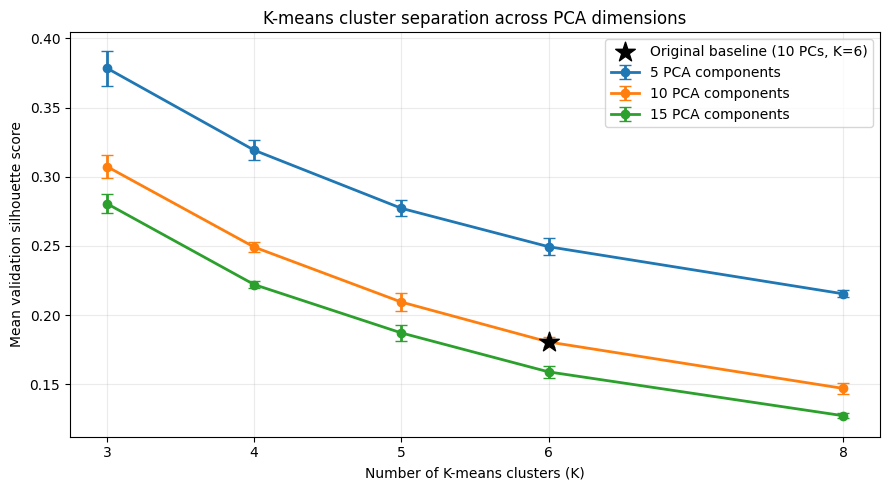

Parameter-comparison plot: SAVED


In [26]:
# Visualize the PCA/K-means parameter comparison.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for n_pcs in PCA_CANDIDATES:

    subset = (
        comparison_summary[
            comparison_summary["n_pcs"] == n_pcs
        ]
        .sort_values("k")
    )

    ax.errorbar(
        subset["k"],
        subset["mean_silhouette"],
        yerr=subset["std_silhouette"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=f"{n_pcs} PCA components",
    )

# Mark the original baseline configuration.
baseline = comparison_summary[
    (comparison_summary["n_pcs"] == 10)
    & (comparison_summary["k"] == 6)
]

ax.scatter(
    baseline["k"],
    baseline["mean_silhouette"],
    marker="*",
    s=220,
    color="black",
    zorder=5,
    label="Original baseline (10 PCs, K=6)",
)

ax.set(
    title="K-means cluster separation across PCA dimensions",
    xlabel="Number of K-means clusters (K)",
    ylabel="Mean validation silhouette score",
)

ax.set_xticks(K_CANDIDATES)
ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()
fig.savefig(
    comparison_dir / "silhouette_vs_k.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Parameter-comparison plot: SAVED")

In [27]:
# Configure a focused stability test for 5 PCs and K=3.

CANDIDATE_N_PCS = 5
CANDIDATE_N_CLUSTERS = 3

# ORIGINAL: Reuse the five random seeds from the baseline.
CANDIDATE_SEEDS = KMEANS_SEEDS

# ADDED: Confirm this candidate was evaluated previously.
candidate_result = comparison_summary.loc[
    (comparison_summary["n_pcs"] == CANDIDATE_N_PCS)
    & (comparison_summary["k"] == CANDIDATE_N_CLUSTERS)
]

assert len(candidate_result) == 1
assert len(fold_pairs) == 3

print("PCA components:", CANDIDATE_N_PCS)
print("K-means clusters:", CANDIDATE_N_CLUSTERS)
print("Random seeds:", CANDIDATE_SEEDS)
print(
    "Previous mean silhouette:",
    round(float(candidate_result["mean_silhouette"].iloc[0]), 4)
)
print("Held-out test particles used: 0")

PCA components: 5
K-means clusters: 3
Random seeds: (0, 1, 2, 3, 4)
Previous mean silhouette: 0.3786
Held-out test particles used: 0


In [28]:

# Evaluate K-means seed stability for 5 PCs and K=3.
# Reason: Check whether different K-means random seeds produce
# consistent validation cluster assignments.


candidate_stability_records = []
candidate_seed_records = []
candidate_cluster_records = []

# Save results separately from the original baseline.
candidate_dir = comparison_dir / "candidate_5pcs_k3"
candidate_dir.mkdir(parents=True, exist_ok=True)

with threadpool_limits(limits=THREADS):

    for fold, (train_idx, val_idx) in enumerate(fold_pairs, start=1):


        assert len(train_idx) == 34264
        assert len(val_idx) == 17132

        assert np.all(
            manifest.iloc[train_idx]["cv_fold"].to_numpy() != 0
        )
        assert np.all(
            manifest.iloc[val_idx]["cv_fold"].to_numpy() == fold
        )

        # ORIGINAL: Select training and validation features.
        train = X[train_idx]
        val = X[val_idx]

        # ORIGINAL: Fit scaling on training particles only.
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled = scaler.transform(val)

        pca = PCA(
            n_components=CANDIDATE_N_PCS,
            svd_solver="randomized",
            random_state=SPLIT_SEED,
        )

        train_z = pca.fit_transform(train_scaled)
        val_z = pca.transform(val_scaled)

        rng = np.random.default_rng(SPLIT_SEED)
        sample_size = min(MAX_SILHOUETTE_SAMPLE, len(val_z))

        sample_idx = rng.choice(
            len(val_z),
            size=sample_size,
            replace=False,
        )

        sample_z = val_z[sample_idx]


        seed_labels = {}

        for seed in CANDIDATE_SEEDS:


            km = KMeans(
                n_clusters=CANDIDATE_N_CLUSTERS,
                random_state=int(seed),
                n_init=20,
            )

            km.fit(train_z)

            val_labels = km.predict(val_z)
            seed_labels[int(seed)] = val_labels

            # Calculate silhouette on the same validation sample.
            sample_labels = val_labels[sample_idx]
            n_sample_clusters = len(np.unique(sample_labels))
            sil = float("nan")

            if 2 <= n_sample_clusters < len(sample_labels):
                sil = float(
                    silhouette_score(sample_z, sample_labels)
                )

            candidate_seed_records.append({
                "fold": fold,
                "seed": int(seed),
                "silhouette_val": sil,
                "train_inertia": float(km.inertia_),
                "n_validation_clusters": int(
                    len(np.unique(val_labels))
                ),
            })

    
            counts = np.bincount(
                val_labels,
                minlength=CANDIDATE_N_CLUSTERS,
            )

            for cluster_idx, count in enumerate(counts, start=1):
                candidate_cluster_records.append({
                    "fold": fold,
                    "seed": int(seed),
                    "cluster": cluster_idx,
                    "n_validation_particles": int(count),
                    "percentage": float(
                        100 * count / len(val_labels)
                    ),
                })

        # Compare clustering assignments across seeds.
        seeds = list(CANDIDATE_SEEDS)

        for i in range(len(seeds)):
            for j in range(i + 1, len(seeds)):

                ari = adjusted_rand_score(
                    seed_labels[int(seeds[i])],
                    seed_labels[int(seeds[j])],
                )

                candidate_stability_records.append({
                    "fold": fold,
                    "seed_a": int(seeds[i]),
                    "seed_b": int(seeds[j]),
                    "ARI_same_validation_images": float(ari),
                })

        print(f"Fold {fold}: candidate stability completed")


candidate_stability = pd.DataFrame(candidate_stability_records)
candidate_seed_metrics = pd.DataFrame(candidate_seed_records)
candidate_cluster_sizes = pd.DataFrame(candidate_cluster_records)


assert len(candidate_stability) == 30
assert len(candidate_seed_metrics) == 15

candidate_stability.to_csv(
    candidate_dir / "seed_stability.csv",
    index=False,
)

candidate_seed_metrics.to_csv(
    candidate_dir / "seed_metrics.csv",
    index=False,
)

candidate_cluster_sizes.to_csv(
    candidate_dir / "cluster_sizes.csv",
    index=False,
)

print("\nCandidate stability test: COMPLETED")
print("PCA components:", CANDIDATE_N_PCS)
print("K-means clusters:", CANDIDATE_N_CLUSTERS)
print("Held-out test particles used: 0")

print("\nARI stability across seeds:")
display(
    candidate_stability.groupby("fold")[
        "ARI_same_validation_images"
    ].agg(["mean", "min", "max"])
)

print("\nSilhouette scores across seeds:")
display(
    candidate_seed_metrics.groupby("fold")[
        "silhouette_val"
    ].agg(["mean", "std"])
)

print("\nCluster sizes for seed 0:")
display(
    candidate_cluster_sizes[
        candidate_cluster_sizes["seed"] == 0
    ].pivot(
        index="fold",
        columns="cluster",
        values="n_validation_particles",
    )
)

print("\nSaved to:", candidate_dir)


Fold 1: candidate stability completed
Fold 2: candidate stability completed
Fold 3: candidate stability completed

Candidate stability test: COMPLETED
PCA components: 5
K-means clusters: 3
Held-out test particles used: 0

ARI stability across seeds:


,mean,min,max
fold,,,
1,0.994251,0.988369,0.999798
2,0.994030,0.988011,0.999835
3,0.998434,0.996085,1.000000



Silhouette scores across seeds:


,mean,std
fold,,
1,0.368489,0.000007
2,0.392941,0.000132
3,0.373787,0.000008



Cluster sizes for seed 0:


cluster,1,2,3
fold,,,
1,7940,5918,3274
2,5854,3328,7950
3,3292,5869,7971



Saved to: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z/parameter_comparison/candidate_5pcs_k3


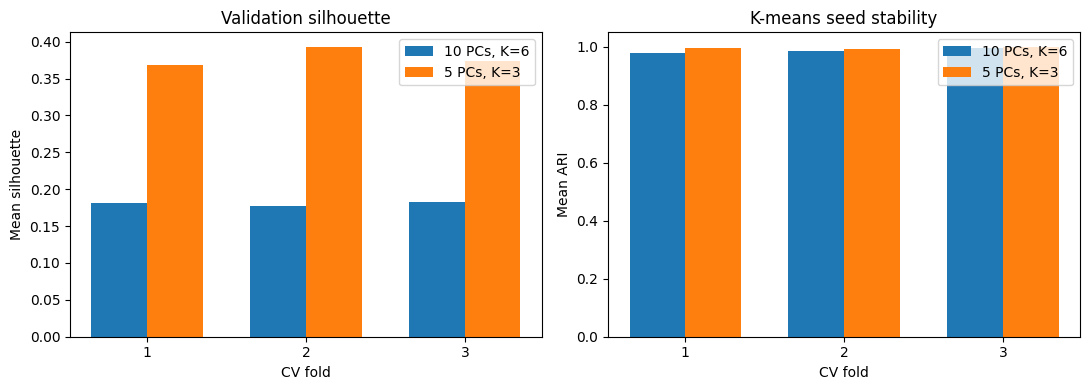

Baseline vs candidate plot: SAVED


In [29]:
# Compare the original baseline with the 5-PC, K=3 candidate.

baseline_sil = seed_metrics.groupby("fold")["silhouette_val"].mean()
candidate_sil = candidate_seed_metrics.groupby("fold")["silhouette_val"].mean()

baseline_ari = stability_metrics.groupby("fold")[
    "ARI_same_validation_images"
].mean()

candidate_ari = candidate_stability.groupby("fold")[
    "ARI_same_validation_images"
].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

fold_positions = np.arange(3)
bar_width = 0.35

axes[0].bar(
    fold_positions - bar_width / 2,
    baseline_sil.reindex([1, 2, 3]),
    bar_width,
    label="10 PCs, K=6",
)

axes[0].bar(
    fold_positions + bar_width / 2,
    candidate_sil.reindex([1, 2, 3]),
    bar_width,
    label="5 PCs, K=3",
)

axes[0].set(
    title="Validation silhouette",
    xlabel="CV fold",
    ylabel="Mean silhouette",
    xticks=fold_positions,
    xticklabels=["1", "2", "3"],
)
axes[0].legend()

axes[1].bar(
    fold_positions - bar_width / 2,
    baseline_ari.reindex([1, 2, 3]),
    bar_width,
    label="10 PCs, K=6",
)

axes[1].bar(
    fold_positions + bar_width / 2,
    candidate_ari.reindex([1, 2, 3]),
    bar_width,
    label="5 PCs, K=3",
)

axes[1].set(
    title="K-means seed stability",
    xlabel="CV fold",
    ylabel="Mean ARI",
    xticks=fold_positions,
    xticklabels=["1", "2", "3"],
    ylim=(0, 1.05),
)
axes[1].legend()

fig.tight_layout()

fig.savefig(
    candidate_dir / "baseline_vs_candidate.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Baseline vs candidate plot: SAVED")

In [30]:
# Prepare aligned CWF images for cluster inspection.

from pathlib import Path
import numpy as np

alignment_dir = (
    PROJECT_ROOT / "outputs" / "camille_cwf_full_alignment"
)

aligned_images = np.load(
    alignment_dir / "aligned_cropped_original.npy",
    mmap_mode="r",
)

assert aligned_images.shape == (57107, 64, 64)
assert len(names) == len(aligned_images)
assert np.array_equal(
    manifest["image_name"].astype(str).to_numpy(),
    cwf_mapping["particle_id"].astype(str).to_numpy(),
)

print("Aligned CWF images: VERIFIED")
print("Image stack:", aligned_images.shape)
print("Image storage: memory-mapped")
print("Held-out test particles selected: 0")

Aligned CWF images: VERIFIED
Image stack: (57107, 64, 64)
Image storage: memory-mapped
Held-out test particles selected: 0


In [31]:
# ADDED: Generate out-of-fold assignments for the 5-PC, K=3 candidate.
# Reason: Link candidate clusters to particle IDs and aligned images.

candidate_predictions = []

with threadpool_limits(limits=THREADS):

    for fold, (train_idx, val_idx) in enumerate(fold_pairs, start=1):

        assert len(train_idx) == 34264
        assert len(val_idx) == 17132

        assert np.all(
            manifest.iloc[train_idx]["cv_fold"].to_numpy() != 0
        )
        assert np.all(
            manifest.iloc[val_idx]["cv_fold"].to_numpy() == fold
        )

        #Select the frozen training and validation particles.
        train = X[train_idx]
        val = X[val_idx]

        # Fit feature scaling on training data only.
        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled = scaler.transform(val)

        # Fit the candidate PCA with five components.
        pca = PCA(
            n_components=CANDIDATE_N_PCS,
            svd_solver="randomized",
            random_state=SPLIT_SEED,
        )

        train_z = pca.fit_transform(train_scaled)
        val_z = pca.transform(val_scaled)
        km = KMeans(
            n_clusters=CANDIDATE_N_CLUSTERS,
            random_state=0,
            n_init=20,
        )

        km.fit(train_z)
        val_labels = km.predict(val_z)
        distances = np.linalg.norm(
            val_z - km.cluster_centers_[val_labels],
            axis=1,
        )

        for position, row_idx in enumerate(val_idx):
            candidate_predictions.append({
                "image_name": str(names[row_idx]),
                "source_row_0based": int(row_idx),
                "cv_fold": int(fold),
                "cluster": int(val_labels[position]) + 1,
                "distance_to_centroid": float(distances[position]),
            })

        print(
            f"Fold {fold}: "
            f"{len(val_idx):,} validation assignments saved"
        )

candidate_pred_table = pd.DataFrame(candidate_predictions)

assert len(candidate_pred_table) == 51396
assert candidate_pred_table["image_name"].is_unique
assert candidate_pred_table["source_row_0based"].is_unique
assert set(candidate_pred_table["image_name"]) == development_ids
assert set(candidate_pred_table["image_name"]).isdisjoint(test_ids)
assert not np.isin(
    candidate_pred_table["source_row_0based"].to_numpy(),
    test_idx,
).any()

candidate_pred_table.to_csv(
    candidate_dir / "out_of_fold_assignments.csv",
    index=False,
)

print("\nCandidate assignments: VERIFIED")
print("Development predictions:", len(candidate_pred_table))
print("Held-out test predictions: 0")
print("Saved to:", candidate_dir / "out_of_fold_assignments.csv")

display(
    candidate_pred_table.groupby(["cv_fold", "cluster"])
    .size()
    .unstack(fill_value=0)
)

Fold 1: 17,132 validation assignments saved
Fold 2: 17,132 validation assignments saved
Fold 3: 17,132 validation assignments saved

Candidate assignments: VERIFIED
Development predictions: 51396
Held-out test predictions: 0
Saved to: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z/parameter_comparison/candidate_5pcs_k3/out_of_fold_assignments.csv


cluster,1,2,3
cv_fold,,,
1,7940,5918,3274
2,5854,3328,7950
3,3292,5869,7971


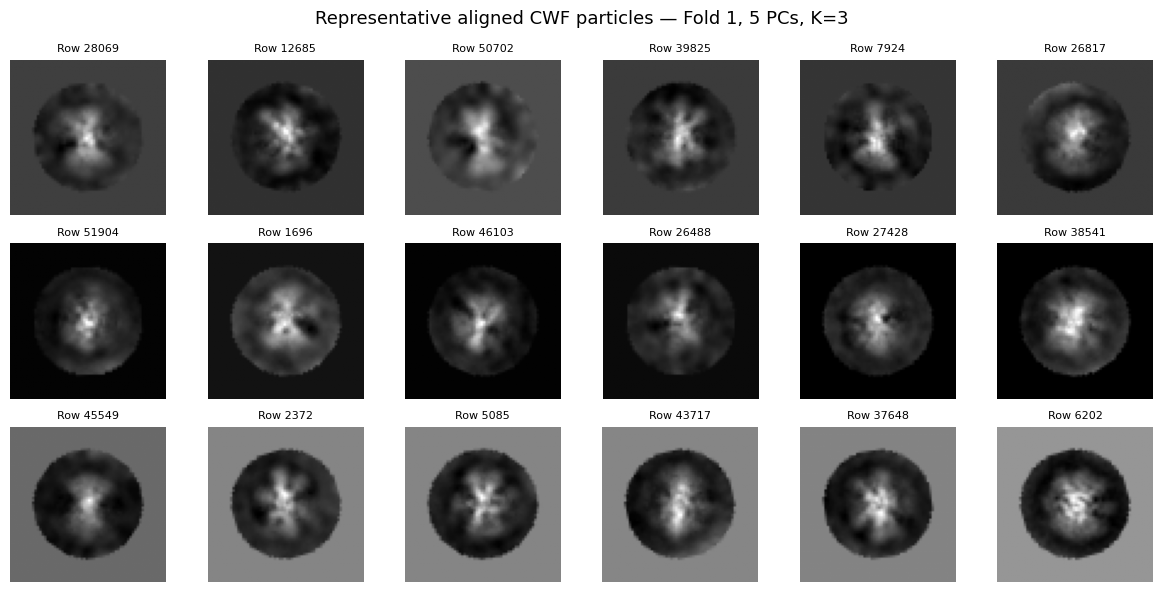

Representative particle visualization: SAVED
Particles displayed: 18
Held-out test particles displayed: 0


In [32]:
#Visualize representative aligned CWF particles from each cluster.

VISUALIZATION_FOLD = 1
PARTICLES_PER_CLUSTER = 6

fig, axes = plt.subplots(
    CANDIDATE_N_CLUSTERS,
    PARTICLES_PER_CLUSTER,
    figsize=(12, 6),
)

selected_rows = []

for cluster in range(1, CANDIDATE_N_CLUSTERS + 1):

    subset = (
        candidate_pred_table.loc[
            (candidate_pred_table["cv_fold"] == VISUALIZATION_FOLD)
            & (candidate_pred_table["cluster"] == cluster)
        ]
        .nsmallest(PARTICLES_PER_CLUSTER, "distance_to_centroid")
    )

    assert len(subset) == PARTICLES_PER_CLUSTER

    # Verify these are development particles, not held-out test.
    assert not np.isin(
        subset["source_row_0based"].to_numpy(),
        test_idx,
    ).any()

    selected_rows.extend(subset["source_row_0based"].tolist())

    for col, (_, particle) in enumerate(subset.iterrows()):
        row_idx = int(particle["source_row_0based"])

        image = np.asarray(aligned_images[row_idx])

        ax = axes[cluster - 1, col]
        ax.imshow(image, cmap="gray", origin="lower")
        ax.axis("off")

        if col == 0:
            ax.set_ylabel(
                f"Cluster {cluster}",
                fontsize=11,
            )

        ax.set_title(
            f"Row {row_idx}",
            fontsize=8,
        )

fig.suptitle(
    "Representative aligned CWF particles — Fold 1, 5 PCs, K=3",
    fontsize=13,
)

fig.tight_layout()
fig.savefig(
    candidate_dir / "representative_particles_fold1.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Representative particle visualization: SAVED")
print("Particles displayed:", len(selected_rows))
print("Held-out test particles displayed: 0")

Background intensity by cluster — Fold 1


,count,mean,std,median
cluster,,,,
1,7940,-0.001991,0.001933,-0.001862
2,5918,0.004348,0.002745,0.003710
3,3274,-0.008768,0.003365,-0.007994


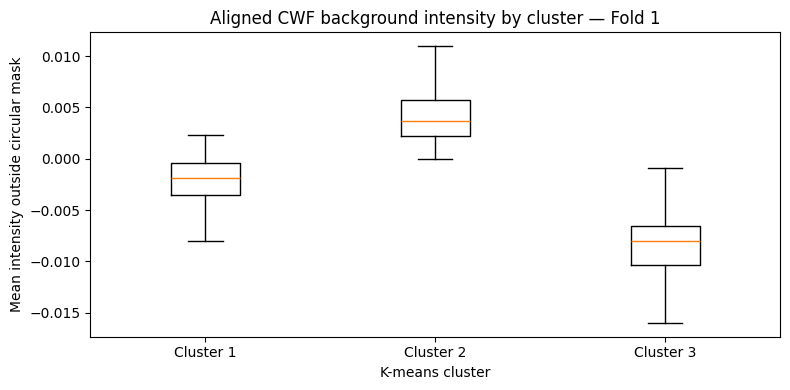

Background intensity analysis: COMPLETED
Held-out test particles analyzed: 0


In [33]:
# Test whether K-means clusters differ in background intensity.
# Reason: Representative images appear to have different background levels.
# This cell does not fit models or access held-out test particles.

# ORIGINAL: Reuse the saved circular mask from Notebook 03.
circle_mask = np.load(
    PROJECT_ROOT
    / "outputs/camille_cwf_full_crops/circle_mask.npy"
).astype(bool)

background_mask = ~circle_mask

assert background_mask.shape == (64, 64)
assert background_mask.any()

# Inspect Fold 1 only; cluster labels are not aligned across folds.
fold1_predictions = candidate_pred_table.loc[
    candidate_pred_table["cv_fold"] == 1
].copy()

assert len(fold1_predictions) == 17132

background_means = []

for start in range(0, len(fold1_predictions), 256):
    batch_rows = fold1_predictions[
        "source_row_0based"
    ].iloc[start:start + 256].to_numpy(dtype=int)

    assert not np.isin(batch_rows, test_idx).any()

    batch_images = np.asarray(
        aligned_images[batch_rows],
        dtype=np.float32,
    )

    batch_means = batch_images[:, background_mask].mean(axis=1)
    background_means.extend(batch_means.tolist())

fold1_predictions["background_mean"] = background_means

# Summarize background levels across clusters.
background_summary = (
    fold1_predictions
    .groupby("cluster")["background_mean"]
    .agg(["count", "mean", "std", "median"])
)

print("Background intensity by cluster — Fold 1")
display(background_summary)

fig, ax = plt.subplots(figsize=(8, 4))

data = [
    fold1_predictions.loc[
        fold1_predictions["cluster"] == cluster,
        "background_mean",
    ].to_numpy()
    for cluster in range(1, CANDIDATE_N_CLUSTERS + 1)
]

ax.boxplot(
    data,
    tick_labels=[f"Cluster {i}" for i in range(1, 4)],
    showfliers=False,
)

ax.set(
    title="Aligned CWF background intensity by cluster — Fold 1",
    xlabel="K-means cluster",
    ylabel="Mean intensity outside circular mask",
)

fig.tight_layout()

fig.savefig(
    candidate_dir / "background_intensity_by_cluster_fold1.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Background intensity analysis: COMPLETED")
print("Held-out test particles analyzed: 0")

In [34]:
# ADDED: Compare particle-region intensity with background intensity.
# Reason: Investigate whether clusters differ in overall image
# brightness rather than specific structural characteristics.

particle_mask = circle_mask

Calculate mean intensity inside the particle region.
particle_means = []

for start in range(0, len(fold1_predictions), 256):

    batch_rows = fold1_predictions[
        "source_row_0based"
    ].iloc[start:start + 256].to_numpy(dtype=int)

    # ADDED: Ensure held-out test particles are excluded.
    assert not np.isin(batch_rows, test_idx).any()

    batch_images = np.asarray(
        aligned_images[batch_rows],
        dtype=np.float32,
    )

    batch_means = batch_images[:, particle_mask].mean(axis=1)

    particle_means.extend(batch_means.tolist())

# ADDED: Add particle-region intensity to the previous results.
fold1_predictions["particle_mean"] = particle_means

# ADDED: Summarize particle and background intensity by cluster.
intensity_summary = (
    fold1_predictions
    .groupby("cluster")
    .agg(
        count=("particle_mean", "size"),
        particle_mean=("particle_mean", "mean"),
        particle_std=("particle_mean", "std"),
        background_mean=("background_mean", "mean"),
        background_std=("background_mean", "std"),
    )
)

print("Particle-region and background intensity — Fold 1")
display(intensity_summary.round(6))

# ADDED: Measure the association between particle and background means.
correlation = fold1_predictions[
    ["particle_mean", "background_mean"]
].corr().iloc[0, 1]

print("Correlation between particle and background intensity:",
      round(float(correlation), 4))

print("Intensity comparison: COMPLETED")
print("Held-out test particles analyzed: 0")

Particle-region and background intensity — Fold 1


,count,particle_mean,particle_std,background_mean,background_std
cluster,,,,,
1,7940,-0.090194,0.225733,-0.001991,0.001933
2,5918,0.665325,0.316589,0.004348,0.002745
3,3274,-0.901613,0.386757,-0.008768,0.003365


Correlation between particle and background intensity: 0.9903
Intensity comparison: COMPLETED
Held-out test particles analyzed: 0


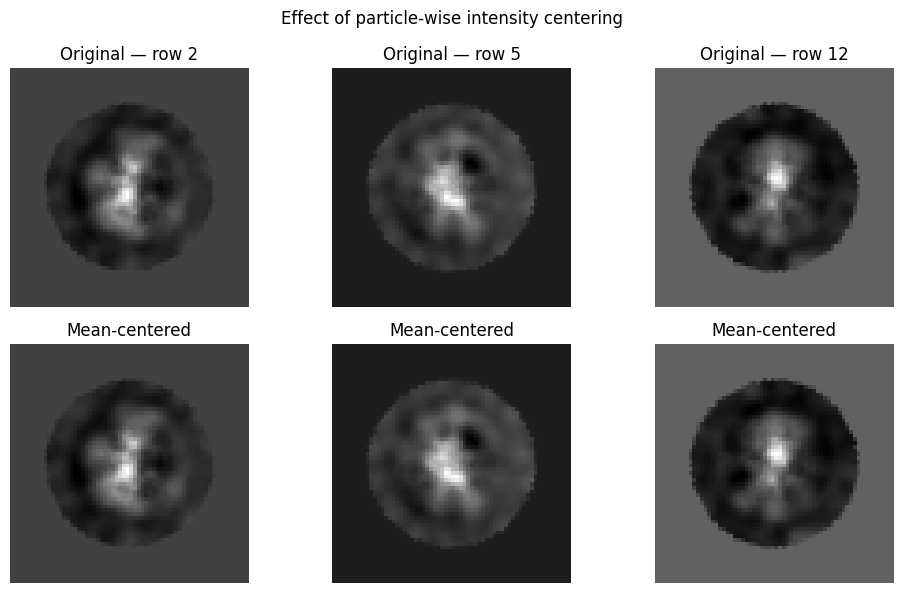

Intensity-centering preview: COMPLETED
Saved images modified: 0
Held-out test particles analyzed: 0


In [35]:
# ADDED: Visualize particle-wise intensity centering.
# Reason: Inspect how removing the mean intensity changes image appearance.
# This does not modify any saved data or fit a model.

# ORIGINAL: Reuse Fold 1 development particles.
example_rows = (
    candidate_pred_table.loc[
        candidate_pred_table["cv_fold"] == 1
    ]
    .groupby("cluster")
    .head(1)["source_row_0based"]
    .to_numpy(dtype=int)
)

assert len(example_rows) == 3
assert not np.isin(example_rows, test_idx).any()

fig, axes = plt.subplots(2, 3, figsize=(10, 6))

for col, row_idx in enumerate(example_rows):

    image = np.asarray(aligned_images[row_idx], dtype=np.float32)

    # ADDED: Calculate the mean intensity inside the circular mask.
    mean_intensity = image[circle_mask].mean()

    # ADDED: Subtract this offset without modifying the original image.
    centered_image = image - mean_intensity

    axes[0, col].imshow(image, cmap="gray", origin="lower")
    axes[0, col].set_title(f"Original — row {row_idx}")

    axes[1, col].imshow(centered_image, cmap="gray", origin="lower")
    axes[1, col].set_title("Mean-centered")

    for row in range(2):
        axes[row, col].axis("off")

fig.suptitle("Effect of particle-wise intensity centering")
fig.tight_layout()

plt.show()

print("Intensity-centering preview: COMPLETED")
print("Saved images modified: 0")
print("Held-out test particles analyzed: 0")

In [36]:
# Verify particle-wise mean centering numerically.
# Reason: Confirm that mean intensity is removed without
# changing the relative image intensity pattern.
# This is a diagnostic only; no saved images or models are changed.

example_rows = (
    candidate_pred_table.loc[
        candidate_pred_table["cv_fold"] == 1
    ]
    .groupby("cluster")
    .head(1)["source_row_0based"]
    .to_numpy(dtype=int)
)

assert len(example_rows) == 3
assert not np.isin(example_rows, test_idx).any()

results = []

for cluster, row_idx in enumerate(example_rows, start=1):
    image = np.asarray(aligned_images[row_idx], dtype=np.float64)

    original_mean = float(image[circle_mask].mean())
    centered = image - original_mean
    centered_mean = float(centered[circle_mask].mean())

    # ADDED: Verify that only a constant offset was removed.
    assert np.allclose(
        image[circle_mask].std(),
        centered[circle_mask].std(),
        rtol=1e-6,
        atol=1e-10,
    )

    assert abs(centered_mean) < 1e-10

    results.append({
        "cluster": cluster,
        "original_mean": original_mean,
        "centered_mean": centered_mean,
        "original_std": float(image[circle_mask].std()),
        "centered_std": float(centered[circle_mask].std()),
    })

display(pd.DataFrame(results).round(6))

print("Intensity-centering numerical check: PASSED")
print("Held-out test particles analyzed: 0")


,cluster,original_mean,centered_mean,original_std,centered_std
0,1,-0.176123,0.0,0.525243,0.525243
1,2,0.687554,0.0,0.600884,0.600884
2,3,-0.743576,0.0,0.501374,0.501374


Intensity-centering numerical check: PASSED
Held-out test particles analyzed: 0


In [37]:

# ADDED: Prepare brightness-corrected radial features.
# Reason: Investigate spatial patterns after removing
# each particle's overall intensity offset.


import numpy as np

#  Reuse the radial regions saved in Notebook 03.
radial_dir = (
    PROJECT_ROOT / "outputs" / "camille_cwf_full_radial"
)

# Load pixel counts for the 24 radial regions.
bin_areas = np.load(
    radial_dir / "bin_pixel_counts.npy"
).astype(np.float64)

assert bin_areas.shape == (24,)
assert np.all(bin_areas > 0)

# Select development particles only.
development_rows = np.flatnonzero(
    manifest["cv_fold"].isin([1, 2, 3]).to_numpy()
)

assert len(development_rows) == 51396
assert not np.isin(development_rows, test_idx).any()

# Create a separate feature matrix.
X_offset_control = np.empty(
    (51396, 48),
    dtype=np.float32,
)

# ORIGINAL: First 24 columns are original intensity sums.
# ORIGINAL: Columns 48:72 are derivative intensity sums.
intensity_blocks = [
    (0, 24),
    (48, 72),
]

for block_number, (start, stop) in enumerate(intensity_blocks):

    # Read intensity sums for development particles.
    sums = np.asarray(
        X[development_rows, start:stop],
        dtype=np.float64,
    )

    # Convert summed intensity to mean intensity per region.
    region_means = sums / bin_areas[None, :]

    # Calculate each particle's area-weighted mean.
    particle_means = sums.sum(axis=1) / bin_areas.sum()

    # Remove the overall brightness offset.
    centered = region_means - particle_means[:, None]

    # Verify area-weighted centering.
    residual = (
        centered * bin_areas[None, :]
    ).sum(axis=1) / bin_areas.sum()

    assert np.max(np.abs(residual)) < 1e-6

    column_start = block_number * 24

    X_offset_control[
        :, column_start:column_start + 24
    ] = centered.astype(np.float32)

#Verify the new experimental feature matrix.
assert X_offset_control.shape == (51396, 48)
assert np.isfinite(X_offset_control).all()

print("Brightness-corrected radial features: PREPARED")
print("Development particles:", X_offset_control.shape[0])
print("Features per particle:", X_offset_control.shape[1])
print("Held-out test particles processed: 0")
print("Original 96-feature matrix: UNCHANGED")


Brightness-corrected radial features: PREPARED
Development particles: 51396
Features per particle: 48
Held-out test particles processed: 0
Original 96-feature matrix: UNCHANGED


In [38]:

# ADDED: Evaluate brightness-corrected radial features with PCA/K-means.
# Reason: Check clustering after removing uniform intensity offsets.

from itertools import combinations

# Save this experiment separately.
offset_dir = candidate_dir / "brightness_control_48"
offset_dir.mkdir(parents=True, exist_ok=True)

offset_metrics = []
offset_stability_records = []
offset_predictions = []

# Map development-only feature rows to their frozen folds.
development_folds = (
    manifest["cv_fold"].to_numpy(dtype=int)[development_rows]
)

assert X_offset_control.shape == (51396, 48)
assert set(np.unique(development_folds)) == {1, 2, 3}
assert not np.isin(development_rows, test_idx).any()

with threadpool_limits(limits=THREADS):

    for fold, (original_train_idx, original_val_idx) in enumerate(
        fold_pairs, start=1
    ):

        train_local = np.flatnonzero(
            (development_folds != fold)
        )
        val_local = np.flatnonzero(
            development_folds == fold
        )

        assert len(train_local) == 34264
        assert len(val_local) == 17132

        assert np.array_equal(
            development_rows[train_local],
            original_train_idx,
        )
        assert np.array_equal(
            development_rows[val_local],
            original_val_idx,
        )


        train = X_offset_control[train_local]
        val = X_offset_control[val_local]


        scaler = StandardScaler()
        train_scaled = scaler.fit_transform(train)
        val_scaled = scaler.transform(val)


        pca = PCA(
            n_components=CANDIDATE_N_PCS,
            svd_solver="randomized",
            random_state=SPLIT_SEED,
        )

        train_z = pca.fit_transform(train_scaled)
        val_z = pca.transform(val_scaled)

        # ADDED: Use the same reproducible silhouette sample.
        rng = np.random.default_rng(SPLIT_SEED)
        sample_idx = rng.choice(
            len(val_z),
            size=min(MAX_SILHOUETTE_SAMPLE, len(val_z)),
            replace=False,
        )

        seed_labels = {}
        silhouettes = []

        for seed in CANDIDATE_SEEDS:

            # Fit K-means on training PCA coordinates.
            km = KMeans(
                n_clusters=CANDIDATE_N_CLUSTERS,
                random_state=int(seed),
                n_init=20,
            )

            km.fit(train_z)
            labels = km.predict(val_z)

            seed_labels[int(seed)] = labels

            # Evaluate separation on validation particles.
            sample_labels = labels[sample_idx]
            n_clusters_in_sample = len(np.unique(sample_labels))

            sil = float("nan")

            if 2 <= n_clusters_in_sample < len(sample_labels):
                sil = float(
                    silhouette_score(
                        val_z[sample_idx],
                        sample_labels,
                    )
                )

            silhouettes.append(sil)

        # Measure agreement across K-means seeds.
        aris = [
            adjusted_rand_score(seed_labels[a], seed_labels[b])
            for a, b in combinations(
                [int(s) for s in CANDIDATE_SEEDS], 2
            )
        ]

        offset_metrics.append({
            "fold": fold,
            "n_pcs": CANDIDATE_N_PCS,
            "k": CANDIDATE_N_CLUSTERS,
            "explained_variance": float(
                pca.explained_variance_ratio_.sum()
            ),
            "mean_silhouette": float(np.nanmean(silhouettes)),
            "mean_ari": float(np.mean(aris)),
        })

        for (seed_a, seed_b), ari in zip(
            combinations([int(s) for s in CANDIDATE_SEEDS], 2),
            aris,
        ):
            offset_stability_records.append({
                "fold": fold,
                "seed_a": seed_a,
                "seed_b": seed_b,
                "ari": float(ari),
            })

        # Preserve seed-0 out-of-fold assignments.
        labels0 = seed_labels[0]

        for local_pos, original_row in enumerate(
            development_rows[val_local]
        ):
            offset_predictions.append({
                "image_name": str(names[original_row]),
                "source_row_0based": int(original_row),
                "cv_fold": fold,
                "cluster": int(labels0[local_pos]) + 1,
            })

        print(
            f"Fold {fold}: silhouette={np.nanmean(silhouettes):.4f}, "
            f"ARI={np.mean(aris):.4f}"
        )

offset_metrics_df = pd.DataFrame(offset_metrics)
offset_stability_df = pd.DataFrame(offset_stability_records)
offset_pred_table = pd.DataFrame(offset_predictions)

assert len(offset_metrics_df) == 3
assert len(offset_stability_df) == 30
assert len(offset_pred_table) == 51396
assert offset_pred_table["image_name"].is_unique
assert set(offset_pred_table["image_name"]) == development_ids
assert set(offset_pred_table["image_name"]).isdisjoint(test_ids)
assert not np.isin(
    offset_pred_table["source_row_0based"].to_numpy(),
    test_idx,
).any()

offset_metrics_df.to_csv(
    offset_dir / "cv_metrics.csv", index=False
)
offset_stability_df.to_csv(
    offset_dir / "seed_stability.csv", index=False
)
offset_pred_table.to_csv(
    offset_dir / "out_of_fold_assignments.csv", index=False
)

print("\nBrightness-control CV: COMPLETED")
print("Development predictions:", len(offset_pred_table))
print("Held-out test predictions: 0")

display(offset_metrics_df)

print("\nCluster sizes (seed 0, labels not aligned between folds):")
display(
    offset_pred_table.groupby(["cv_fold", "cluster"])
    .size()
    .unstack(fill_value=0)
)

print("\nSaved to:", offset_dir)


Fold 1: silhouette=0.1595, ARI=0.9531
Fold 2: silhouette=0.1650, ARI=0.9673
Fold 3: silhouette=0.1576, ARI=0.9642

Brightness-control CV: COMPLETED
Development predictions: 51396
Held-out test predictions: 0


,fold,n_pcs,k,explained_variance,mean_silhouette,mean_ari
0,1,5,3,0.525434,0.159530,0.953083
1,2,5,3,0.527056,0.165038,0.967305
2,3,5,3,0.526765,0.157584,0.964235



Cluster sizes (seed 0, labels not aligned between folds):


cluster,1,2,3
cv_fold,,,
1,6523,4134,6475
2,6493,4113,6526
3,6474,4063,6595



Saved to: /Users/kr/ml4ls/outputs/validation_09/20261111T113524Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48


In [39]:

# Compare brightness association for both clustering solutions.
# Reason: Check whether the new clusters still reflect image intensity.

original_fold1 = fold1_predictions[
    ["source_row_0based", "cluster",
     "particle_mean", "background_mean"]
].copy()

original_fold1 = original_fold1.rename(
    columns={"cluster": "original_cluster"}
)

control_fold1 = offset_pred_table.loc[
    offset_pred_table["cv_fold"] == 1,
    ["source_row_0based", "cluster"]
].rename(columns={"cluster": "control_cluster"})

comparison = original_fold1.merge(
    control_fold1,
    on="source_row_0based",
    how="inner",
    validate="one_to_one",
)

assert len(comparison) == 17132
assert not np.isin(
    comparison["source_row_0based"].to_numpy(),
    test_idx,
).any()

# Calculate how much intensity variation is associated
# with cluster membership (eta-squared, between 0 and 1).
def eta_squared(values, labels):
    values = np.asarray(values, dtype=float)
    labels = np.asarray(labels)

    overall_mean = values.mean()
    total_ss = np.sum((values - overall_mean) ** 2)

    between_ss = sum(
        np.sum(labels == label) *
        (values[labels == label].mean() - overall_mean) ** 2
        for label in np.unique(labels)
    )

    return float(between_ss / total_ss)

results = []

for label_col, representation in [
    ("original_cluster", "Original 96 features"),
    ("control_cluster", "Brightness-control 48 features"),
]:
    results.append({
        "representation": representation,
        "particle_intensity_eta2": eta_squared(
            comparison["particle_mean"], comparison[label_col]
        ),
        "background_intensity_eta2": eta_squared(
            comparison["background_mean"], comparison[label_col]
        ),
    })

association_df = pd.DataFrame(results)

print("Brightness association by clustering representation — Fold 1")
display(association_df.round(4))

# Compare how similarly the two models group particles.
agreement = adjusted_rand_score(
    comparison["original_cluster"],
    comparison["control_cluster"],
)

print(f"\nAgreement between original and control clusters (ARI): {agreement:.4f}")

print("\nParticle intensity by brightness-control cluster:")
display(
    comparison.groupby("control_cluster")["particle_mean"]
    .agg(["count", "mean", "std"])
    .round(4)
)

association_df.to_csv(
    offset_dir / "brightness_association_fold1.csv",
    index=False,
)

print("\nBrightness-association diagnostic: COMPLETED")
print("Held-out test particles analyzed: 0")


Brightness association by clustering representation — Fold 1


,representation,particle_intensity_eta2,background_intensity_eta2
0,Original 96 features,0.7822,0.7708
1,Brightness-control 48 features,0.0055,0.0063



Agreement between original and control clusters (ARI): 0.0574

Particle intensity by brightness-control cluster:


,count,mean,std
control_cluster,,,
1,6523,-0.0157,0.7106
2,4134,-0.0283,0.7568
3,6475,0.0755,0.4180



Brightness-association diagnostic: COMPLETED
Held-out test particles analyzed: 0


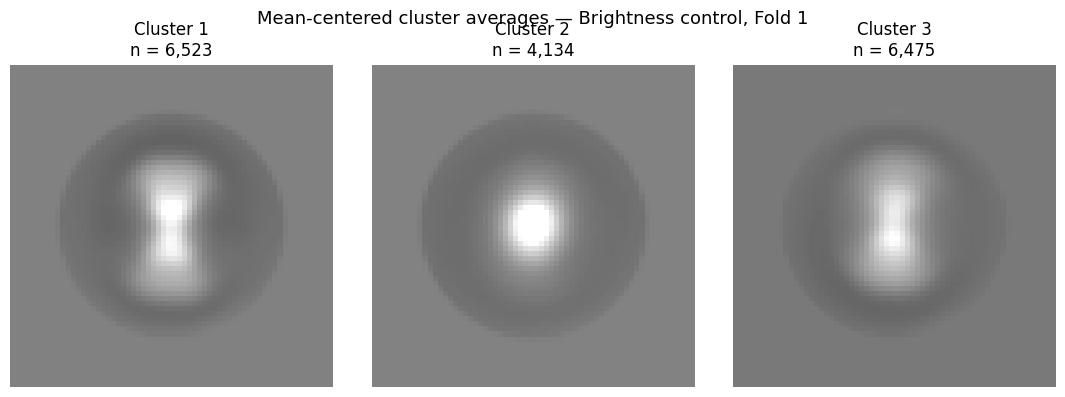

Brightness-control cluster averages: COMPLETED
Particles per cluster: [6523, 4134, 6475]
Shared contrast limit: 1.744756
Held-out test particles analyzed: 0


In [40]:

# ADDED: Visualize mean aligned particles for brightness-control clusters.
# Reason: Investigate whether the new groups show spatial differences.


CONTROL_VISUALIZATION_FOLD = 1
IMAGE_BATCH_SIZE = 256

control_fold = offset_pred_table.loc[
    offset_pred_table["cv_fold"] == CONTROL_VISUALIZATION_FOLD
].copy()

assert len(control_fold) == 17132

cluster_mean_images = []
cluster_sizes = []

for cluster in range(1, CANDIDATE_N_CLUSTERS + 1):

    rows = control_fold.loc[
        control_fold["cluster"] == cluster,
        "source_row_0based"
    ].to_numpy(dtype=int)

    assert len(rows) > 0
    assert not np.isin(rows, test_idx).any()

    image_sum = np.zeros((64, 64), dtype=np.float64)

    for start in range(0, len(rows), IMAGE_BATCH_SIZE):

        batch_rows = rows[start:start + IMAGE_BATCH_SIZE]

        images = np.asarray(
            aligned_images[batch_rows],
            dtype=np.float32,
        )

        particle_means = images[:, circle_mask].mean(axis=1)

        centered_images = (
            images - particle_means[:, None, None]
        )

        image_sum += centered_images.sum(
            axis=0,
            dtype=np.float64,
        )

    cluster_mean_images.append(image_sum / len(rows))
    cluster_sizes.append(len(rows))

mean_stack = np.stack(cluster_mean_images)

contrast_limit = float(
    np.percentile(
        np.abs(mean_stack[:, circle_mask]),
        99,
    )
)

assert contrast_limit > 0

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

for idx, ax in enumerate(axes):

    im = ax.imshow(
        mean_stack[idx],
        cmap="gray",
        origin="lower",
        vmin=-contrast_limit,
        vmax=contrast_limit,
    )

    ax.set_title(
        f"Cluster {idx + 1}\n"
        f"n = {cluster_sizes[idx]:,}"
    )

    ax.axis("off")

fig.suptitle(
    "Mean-centered cluster averages — Brightness control, Fold 1",
    fontsize=13,
)

fig.tight_layout()

fig.savefig(
    offset_dir / "cluster_average_images_fold1.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Brightness-control cluster averages: COMPLETED")
print("Particles per cluster:", cluster_sizes)
print("Shared contrast limit:", round(contrast_limit, 6))
print("Held-out test particles analyzed: 0")


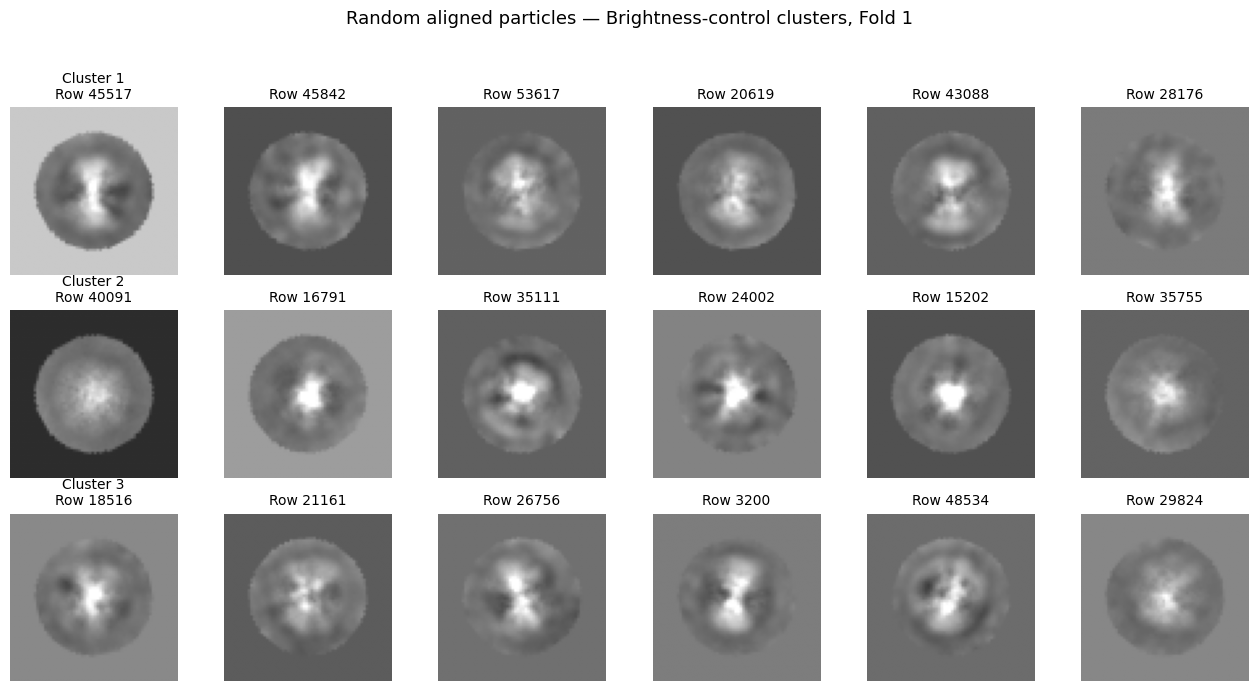

Random particle inspection: COMPLETED
Particles displayed: 18
Shared contrast limit: 2.143306
Held-out test particles displayed: 0


In [41]:

# Show random individual particles from brightness-control clusters.
# Reason: Check whether differences in cluster averages are
# visible in typical particles, not only in their averages.

PARTICLES_PER_CLUSTER = 6
RANDOM_SEED = 42

selected_rows = []
selected_clusters = []

for cluster in range(1, CANDIDATE_N_CLUSTERS + 1):

    subset = offset_pred_table.loc[
        (offset_pred_table["cv_fold"] == 1)
        & (offset_pred_table["cluster"] == cluster)
    ]

    # Random sampling
    examples = subset.sample(
        n=PARTICLES_PER_CLUSTER,
        random_state=RANDOM_SEED,
    )

    rows = examples["source_row_0based"].to_numpy(dtype=int)

    assert not np.isin(rows, test_idx).any()

    selected_rows.extend(rows.tolist())
    selected_clusters.extend([cluster] * len(rows))

sample_images = np.stack([
    np.asarray(aligned_images[row], dtype=np.float32)
    for row in selected_rows
])

sample_means = sample_images[:, circle_mask].mean(axis=1)
centered_images = sample_images - sample_means[:, None, None]

contrast_limit = float(
    np.percentile(
        np.abs(centered_images[:, circle_mask]),
        99,
    )
)

fig, axes = plt.subplots(3, 6, figsize=(13, 7))

for idx, (row_idx, cluster) in enumerate(
    zip(selected_rows, selected_clusters)
):

    row = idx // PARTICLES_PER_CLUSTER
    col = idx % PARTICLES_PER_CLUSTER

    ax = axes[row, col]

    ax.imshow(
        centered_images[idx],
        cmap="gray",
        origin="lower",
        vmin=-contrast_limit,
        vmax=contrast_limit,
    )

    title = f"Row {row_idx}"

    if col == 0:
        title = f"Cluster {cluster}\n{title}"

    ax.set_title(title, fontsize=10)
    ax.axis("off")

fig.suptitle(
    "Random aligned particles — Brightness-control clusters, Fold 1",
    fontsize=13,
)

fig.tight_layout(rect=(0, 0, 1, 0.95))

fig.savefig(
    offset_dir / "random_particles_by_cluster_fold1.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Random particle inspection: COMPLETED")
print("Particles displayed:", len(selected_rows))
print("Shared contrast limit:", round(contrast_limit, 6))
print("Held-out test particles displayed: 0")


Contrast association — Fold 1


,representation,contrast_eta2
0,Original 96 features,0.0126
1,Brightness-control 48 features,0.0804



Contrast by brightness-control cluster:


,count,mean,std,median
control_cluster,,,,
1,6523,0.5273,0.0621,0.5196
2,4134,0.5390,0.0932,0.5171
3,6475,0.4899,0.0610,0.4806


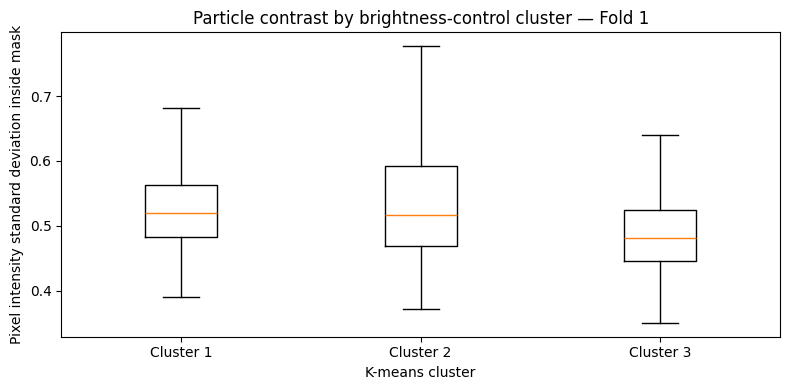

Contrast diagnostic: COMPLETED
Held-out test particles analyzed: 0


In [42]:

# Check whether brightness-control clusters track image contrast.
# Reason: Mean-centering removes brightness offsets but not contrast differences.


contrast_rows = comparison["source_row_0based"].to_numpy(dtype=int)

assert len(contrast_rows) == 17132
assert not np.isin(contrast_rows, test_idx).any()
particle_contrasts = []

for start in range(0, len(contrast_rows), 256):

    batch_rows = contrast_rows[start:start + 256]

    images = np.asarray(
        aligned_images[batch_rows],
        dtype=np.float32,
    )

    batch_contrast = images[:, circle_mask].std(
        axis=1,
        dtype=np.float64,
    )

    particle_contrasts.extend(batch_contrast.tolist())

contrast_comparison = comparison.copy()
contrast_comparison["particle_contrast"] = particle_contrasts

#Compare contrast association for both cluster solutions.
contrast_association = pd.DataFrame([
    {
        "representation": "Original 96 features",
        "contrast_eta2": eta_squared(
            contrast_comparison["particle_contrast"],
            contrast_comparison["original_cluster"],
        ),
    },
    {
        "representation": "Brightness-control 48 features",
        "contrast_eta2": eta_squared(
            contrast_comparison["particle_contrast"],
            contrast_comparison["control_cluster"],
        ),
    },
])

print("Contrast association — Fold 1")
display(contrast_association.round(4))

# Summarize contrast within the brightness-control clusters.
contrast_summary = (
    contrast_comparison
    .groupby("control_cluster")["particle_contrast"]
    .agg(["count", "mean", "std", "median"])
)

print("\nContrast by brightness-control cluster:")
display(contrast_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 4))

contrast_data = [
    contrast_comparison.loc[
        contrast_comparison["control_cluster"] == cluster,
        "particle_contrast",
    ].to_numpy()
    for cluster in range(1, 4)
]

ax.boxplot(
    contrast_data,
    tick_labels=["Cluster 1", "Cluster 2", "Cluster 3"],
    showfliers=False,
)

ax.set(
    title="Particle contrast by brightness-control cluster — Fold 1",
    xlabel="K-means cluster",
    ylabel="Pixel intensity standard deviation inside mask",
)

fig.tight_layout()

fig.savefig(
    offset_dir / "contrast_by_cluster_fold1.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

contrast_association.to_csv(
    offset_dir / "contrast_association_fold1.csv",
    index=False,
)

print("Contrast diagnostic: COMPLETED")
print("Held-out test particles analyzed: 0")


In [40]:

display(contrast_association.round(4))


,representation,contrast_eta2
0,Original 96 features,0.0126
1,Brightness-control 48 features,0.0804



### 9.8 Brightness-control experiment: conclusions

**Original model**
- Features: 96 radial measurements
- PCA components: 5
- K-means clusters: 3
- Mean silhouette: approximately 0.378
- Seed-stability ARI: approximately 0.996
- Strong association with particle brightness (Fold 1 η² = 0.7822)

**Brightness-control model**
- Features: 48 centered radial intensity measurements
- PCA components: 5
- K-means clusters: 3
- Mean silhouette: approximately 0.161
- Seed-stability ARI: approximately 0.962
- Very weak association with particle brightness (Fold 1 η² = 0.0055)
- Modest association with particle contrast (Fold 1 η² = 0.0804)

**Interpretation**

The original clustering is strongly associated with overall image
brightness. The brightness-control representation substantially reduces
this association and produces different spatial patterns in cluster
average images.

However, the control also excludes positive-pixel fraction features.
The observed changes cannot be attributed solely to intensity centering.

The brightness-control clusters are not yet verified protein
conformations. Differences could reflect viewing orientation, alignment,
image contrast, or other processing characteristics.

**Next steps**
1. Investigate alignment uncertainty across the new clusters.
2. Examine cluster averages and particle examples in Notebook 08.
3. Avoid biological conformation labels without additional evidence.

**Data handling**
- Three frozen development folds were used for cross-validation.
- The 5,711 held-out test particles remain unused.
- Original feature files and baseline results are preserved.


In [43]:

from pathlib import Path

alignment_dir = (
    PROJECT_ROOT / "outputs" / "camille_cwf_full_alignment"
)

assert alignment_dir.exists(), (
    f"Alignment directory not found: {alignment_dir}"
)

print("Alignment directory:")
print(alignment_dir)

print("\nAvailable files:")
for path in sorted(alignment_dir.iterdir()):
    print(" -", path.name)

metadata_files = sorted(
    path
    for path in alignment_dir.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {
        ".csv", ".tsv", ".json", ".parquet"
    }
)

print("\nMetadata files found:", len(metadata_files))

for path in metadata_files:
    print("\nFile:", path.relative_to(PROJECT_ROOT))

    # ADDED: Read only the first three rows of CSV/TSV files.
    if path.suffix.lower() in {".csv", ".tsv"}:
        separator = "\t" if path.suffix.lower() == ".tsv" else ","

        preview = pd.read_csv(
            path,
            sep=separator,
            nrows=3,
        )

        print("Columns:", list(preview.columns))
        display(preview)

print("\nAlignment metadata inspection: COMPLETED")
print("Clustering models retrained: 0")
print("Held-out test particle images analyzed: 0")


Alignment directory:
/Users/kr/ml4ls/outputs/camille_cwf_full_alignment

Available files:
 - aligned_cropped_derivative.npy
 - aligned_cropped_original.npy
 - alignment.csv
 - alignment_bars.png
 - image_names.npy
 - preview.png
 - settings.json
 - transforms.npz

Metadata files found: 2

File: outputs/camille_cwf_full_alignment/alignment.csv
Columns: ['image_name', 'angle_degrees', 'aligned_y', 'aligned_x', 'flip_vertical', 'flip_horizontal', 'axis_ratio', 'secondary_contrast', 'centroid_y', 'centroid_x', 'axis_y', 'axis_x', 'secondary_y', 'secondary_x', 'secondary_length', 'status']


,image_name,angle_degrees,aligned_y,aligned_x,flip_vertical,flip_horizontal,axis_ratio,secondary_contrast,centroid_y,centroid_x,axis_y,axis_x,secondary_y,secondary_x,secondary_length,status
0,000001@J598/restack/batch_0_restacked.mrc,39.171160,31.5,31.5,False,True,1.251765,0.183598,31.906475,31.617506,-0.775263,0.631639,-16.353736,4.281755,16.904973,ok
1,000002@J598/restack/batch_0_restacked.mrc,17.068911,31.5,31.5,False,True,1.701311,0.393716,29.568826,33.062753,-0.955952,0.293522,-15.393230,-2.956904,15.674655,ok
2,000003@J598/restack/batch_0_restacked.mrc,-64.698854,31.5,31.5,True,False,1.159615,0.338081,31.635171,30.984252,0.427376,0.904074,-5.542497,16.280043,17.197648,ok



File: outputs/camille_cwf_full_alignment/settings.json

Alignment metadata inspection: COMPLETED
Clustering models retrained: 0
Held-out test particle images analyzed: 0


In [44]:

# ADDED: Compare alignment status across brightness-control clusters.
# Reason: Check whether cluster differences may be related to
# uncertainty in the particle alignment procedure.

alignment_metadata = pd.read_csv(
    alignment_dir / "alignment.csv",
    usecols=["image_name", "status"],
)

assert alignment_metadata["image_name"].is_unique
assert alignment_metadata["image_name"].notna().all()
assert alignment_metadata["status"].notna().all()

# Use Fold 1 brightness-control predictions only.
fold1_clusters = offset_pred_table.loc[
    offset_pred_table["cv_fold"] == 1,
    ["image_name", "source_row_0based", "cluster"],
].copy()

assert len(fold1_clusters) == 17132
assert fold1_clusters["image_name"].is_unique

# Confirm that held-out test particles are excluded.
assert not np.isin(
    fold1_clusters["source_row_0based"].to_numpy(),
    test_idx,
).any()

# Match particles using their verified image names.
alignment_comparison = fold1_clusters.merge(
    alignment_metadata,
    on="image_name",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# Verify every selected particle has alignment metadata.
assert (
    alignment_comparison["_merge"] == "both"
).all(), "Some particles have no matching alignment record."

assert len(alignment_comparison) == 17132

alignment_comparison = alignment_comparison.drop(
    columns="_merge"
)
alignment_counts = pd.crosstab(
    alignment_comparison["cluster"],
    alignment_comparison["status"],
)

alignment_percentages = (
    alignment_counts.div(
        alignment_counts.sum(axis=1),
        axis=0,
    ) * 100
)

print("Alignment-status counts — Fold 1")
display(alignment_counts)

print("\nAlignment-status percentages — Fold 1")
display(alignment_percentages.round(2))

print("\nOverall Fold 1 alignment-status percentages:")
display(
    (
        alignment_comparison["status"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
)

# ADDED: Save results without modifying existing predictions.
alignment_counts.to_csv(
    offset_dir / "alignment_status_counts_fold1.csv"
)

alignment_percentages.to_csv(
    offset_dir / "alignment_status_percentages_fold1.csv"
)

print("\nAlignment-quality comparison: COMPLETED")
print("Particles analyzed:", len(alignment_comparison))
print("Held-out test particles analyzed: 0")
print("Clustering models retrained: 0")


Alignment-status counts — Fold 1


status,ok,uncertain_axis,uncertain_secondary
cluster,,,
1,5890,114,519
2,3268,719,147
3,5634,420,421



Alignment-status percentages — Fold 1


status,ok,uncertain_axis,uncertain_secondary
cluster,,,
1,90.30,1.75,7.96
2,79.05,17.39,3.56
3,87.01,6.49,6.50



Overall Fold 1 alignment-status percentages:


status
ok                     86.34
uncertain_axis          7.31
uncertain_secondary     6.34
Name: proportion, dtype: float64


Alignment-quality comparison: COMPLETED
Particles analyzed: 17132
Held-out test particles analyzed: 0
Clustering models retrained: 0


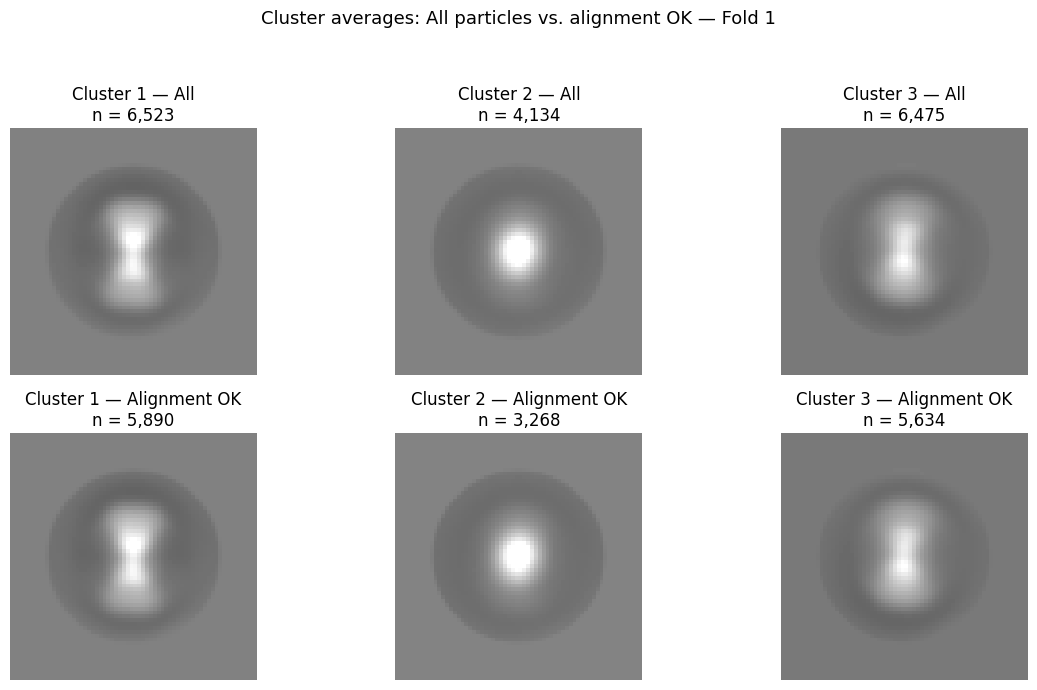

Alignment-filtered cluster averages: COMPLETED
All particle counts: [6523, 4134, 6475]
Alignment-OK counts: [5890, 3268, 5634]
Cluster assignments modified: 0
Held-out test particles analyzed: 0


In [45]:

# Compare cluster averages before and after filtering
# particles with uncertain alignment status.
# Reason: Investigate whether distinctive average shapes persist
# when only particles marked "ok" are included.

ok_mean_images = []
ok_cluster_sizes = []

for cluster in range(1, CANDIDATE_N_CLUSTERS + 1):

    # Select particles assigned to this cluster
    # whose alignment status is "ok".
    rows = alignment_comparison.loc[
        (alignment_comparison["cluster"] == cluster)
        & (alignment_comparison["status"] == "ok"),
        "source_row_0based",
    ].to_numpy(dtype=int)

    assert len(rows) > 0
    assert not np.isin(rows, test_idx).any()

    image_sum = np.zeros((64, 64), dtype=np.float64)

    #  Process images in small batches.
    for start in range(0, len(rows), 256):

        batch_rows = rows[start:start + 256]

        images = np.asarray(
            aligned_images[batch_rows],
            dtype=np.float32,
        )

        # Use the same particle-wise centering
        # as our previous cluster-average visualization.
        means = images[:, circle_mask].mean(axis=1)

        centered = images - means[:, None, None]

        image_sum += centered.sum(
            axis=0,
            dtype=np.float64,
        )

    ok_mean_images.append(image_sum / len(rows))
    ok_cluster_sizes.append(len(rows))

ok_mean_stack = np.stack(ok_mean_images)

# Use identical contrast settings for all six panels.
combined_means = np.concatenate(
    [mean_stack, ok_mean_stack],
    axis=0,
)

shared_limit = float(
    np.percentile(
        np.abs(combined_means[:, circle_mask]),
        99,
    )
)

assert shared_limit > 0

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for idx in range(CANDIDATE_N_CLUSTERS):

    #Average using all particles.
    axes[0, idx].imshow(
        mean_stack[idx],
        cmap="gray",
        origin="lower",
        vmin=-shared_limit,
        vmax=shared_limit,
    )

    axes[0, idx].set_title(
        f"Cluster {idx + 1} — All\n"
        f"n = {cluster_sizes[idx]:,}"
    )

    # Average using only status="ok" particles.
    axes[1, idx].imshow(
        ok_mean_stack[idx],
        cmap="gray",
        origin="lower",
        vmin=-shared_limit,
        vmax=shared_limit,
    )

    axes[1, idx].set_title(
        f"Cluster {idx + 1} — Alignment OK\n"
        f"n = {ok_cluster_sizes[idx]:,}"
    )

    axes[0, idx].axis("off")
    axes[1, idx].axis("off")

fig.suptitle(
    "Cluster averages: All particles vs. alignment OK — Fold 1",
    fontsize=13,
)

fig.tight_layout(rect=(0, 0, 1, 0.94))

fig.savefig(
    offset_dir / "cluster_averages_alignment_ok_fold1.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

print("Alignment-filtered cluster averages: COMPLETED")
print("All particle counts:", cluster_sizes)
print("Alignment-OK counts:", ok_cluster_sizes)
print("Cluster assignments modified: 0")
print("Held-out test particles analyzed: 0")



### Alignment-quality diagnostic: conclusions

We compared the brightness-control K-means clusters using all
Fold 1 validation particles and only particles with alignment
status `ok`.

**Alignment results**
- Cluster 1: 90.30% alignment OK (5,890 / 6,523)
- Cluster 2: 79.05% alignment OK (3,268 / 4,134)
- Cluster 3: 87.01% alignment OK (5,634 / 6,475)

Cluster 2 had the highest uncertain-axis percentage (17.39%).

**Image-average comparison**

The characteristic average patterns remained visible after
restricting each cluster to alignment-OK particles:

- Cluster 1: elongated, hourglass-like central signal
- Cluster 2: compact, approximately circular central signal
- Cluster 3: vertically elongated central signal

**Scientific interpretation**

The average-image differences are not solely explained by
particles marked as uncertain during alignment.

However, the clusters may reflect viewing orientation,
residual alignment effects, structural heterogeneity, or
other imaging characteristics.

The current evidence does not establish three distinct
protein conformations.

**Next stage**

Use Notebook 08 for further exploratory examination of
cluster examples and average images, reusing the verified
out-of-fold assignments from Notebook 09.

Preserve the original baseline, brightness-control results,
and frozen held-out test set.


### Cross-fold diagnostic validation

In [46]:
# Cross-fold diagnostic validation for all three folds.
# Reason: Verify brightness, contrast, and alignment findings
# beyond the Fold 1 investigation.


# ADDED: Match both clustering solutions using verified particle IDs.
match_columns = [
    "image_name",
    "source_row_0based",
    "cv_fold",
]

original_predictions = candidate_pred_table[
    match_columns + ["cluster"]
].rename(columns={"cluster": "original_cluster"})

control_predictions = offset_pred_table[
    match_columns + ["cluster"]
].rename(columns={"cluster": "control_cluster"})

cross_fold_data = control_predictions.merge(
    original_predictions,
    on=match_columns,
    how="inner",
    validate="one_to_one",
)

cross_fold_data = cross_fold_data.merge(
    alignment_metadata[["image_name", "status"]],
    on="image_name",
    how="left",
    validate="one_to_one",
)

assert len(cross_fold_data) == 51396
assert cross_fold_data["image_name"].is_unique
assert cross_fold_data["status"].notna().all()
assert set(cross_fold_data["image_name"]) == development_ids

rows = cross_fold_data[
    "source_row_0based"
].to_numpy(dtype=int)

assert not np.isin(rows, test_idx).any()
assert set(rows) == set(development_rows)

# Calculate particle brightness, background brightness,
# and contrast using memory-safe image batches.
particle_mean_values = np.empty(len(rows), dtype=np.float64)
background_mean_values = np.empty(len(rows), dtype=np.float64)
contrast_values = np.empty(len(rows), dtype=np.float64)

for start in range(0, len(rows), 256):

    stop = min(start + 256, len(rows))
    batch_rows = rows[start:stop]

    images = np.asarray(
        aligned_images[batch_rows],
        dtype=np.float32,
    )

    inside = images[:, circle_mask]
    outside = images[:, ~circle_mask]

    particle_mean_values[start:stop] = inside.mean(
        axis=1, dtype=np.float64
    )

    background_mean_values[start:stop] = outside.mean(
        axis=1, dtype=np.float64
    )

    contrast_values[start:stop] = inside.std(
        axis=1, dtype=np.float64
    )

cross_fold_data["particle_mean"] = particle_mean_values
cross_fold_data["background_mean"] = background_mean_values
cross_fold_data["particle_contrast"] = contrast_values

# Calculate the same eta-squared diagnostics
# independently for each validation fold.
diagnostic_records = []
alignment_records = []

for fold in [1, 2, 3]:

    fold_data = cross_fold_data.loc[
        cross_fold_data["cv_fold"] == fold
    ]

    assert len(fold_data) == 17132

    for representation, label_column in [
        ("Original 96", "original_cluster"),
        ("Brightness-control 48", "control_cluster"),
    ]:

        diagnostic_records.append({
            "fold": fold,
            "representation": representation,
            "brightness_eta2": eta_squared(
                fold_data["particle_mean"],
                fold_data[label_column],
            ),
            "background_eta2": eta_squared(
                fold_data["background_mean"],
                fold_data[label_column],
            ),
            "contrast_eta2": eta_squared(
                fold_data["particle_contrast"],
                fold_data[label_column],
            ),
        })

    # Alignment percentages for each control cluster.
    # Cluster numbers are interpreted separately within each fold.
    status_percentages = pd.crosstab(
        fold_data["control_cluster"],
        fold_data["status"],
        normalize="index",
    ) * 100

    status_percentages = status_percentages.reindex(
        index=[1, 2, 3],
        columns=[
            "ok",
            "uncertain_axis",
            "uncertain_secondary",
        ],
        fill_value=0,
    )

    cluster_counts = (
        fold_data["control_cluster"]
        .value_counts()
    )

    for cluster in [1, 2, 3]:

        alignment_records.append({
            "fold": fold,
            "cluster": cluster,
            "particles": int(cluster_counts[cluster]),
            "ok_pct": status_percentages.loc[
                cluster, "ok"
            ],
            "uncertain_axis_pct": status_percentages.loc[
                cluster, "uncertain_axis"
            ],
            "uncertain_secondary_pct": status_percentages.loc[
                cluster, "uncertain_secondary"
            ],
        })

# Create the cross-fold results.
cross_fold_diagnostics = pd.DataFrame(diagnostic_records)
cross_fold_alignment = pd.DataFrame(alignment_records)

assert len(cross_fold_diagnostics) == 6
assert len(cross_fold_alignment) == 9

print("CROSS-FOLD BRIGHTNESS AND CONTRAST DIAGNOSTICS")
display(cross_fold_diagnostics.round(4))

print("\nCROSS-FOLD ALIGNMENT STATUS — BRIGHTNESS CONTROL")
display(cross_fold_alignment.round(2))


cross_fold_diagnostics.to_csv(
    offset_dir / "cross_fold_diagnostics.csv",
    index=False,
)

cross_fold_alignment.to_csv(
    offset_dir / "cross_fold_alignment_status.csv",
    index=False,
)

print("\nCross-fold diagnostics: COMPLETED")
print("Development particles analyzed:", len(cross_fold_data))
print("Validation folds analyzed: 3")
print("Held-out test particles analyzed: 0")
print("Models retrained: 0")
print("Results saved to:", offset_dir)


CROSS-FOLD BRIGHTNESS AND CONTRAST DIAGNOSTICS


,fold,representation,brightness_eta2,background_eta2,contrast_eta2
0,1,Original 96,0.7822,0.7708,0.0126
1,1,Brightness-control 48,0.0055,0.0063,0.0804
2,2,Original 96,0.7823,0.7683,0.0205
3,2,Brightness-control 48,0.0061,0.0074,0.0788
4,3,Original 96,0.7790,0.7676,0.0152
5,3,Brightness-control 48,0.0057,0.0070,0.0833



CROSS-FOLD ALIGNMENT STATUS — BRIGHTNESS CONTROL


,fold,cluster,particles,ok_pct,uncertain_axis_pct,uncertain_secondary_pct
0,1,1,6523,90.30,1.75,7.96
1,1,2,4134,79.05,17.39,3.56
2,1,3,6475,87.01,6.49,6.50
3,2,1,6493,90.50,1.89,7.61
4,2,2,4113,79.21,17.55,3.23
5,2,3,6526,86.64,6.63,6.73
6,3,1,6474,91.27,1.68,7.04
7,3,2,4063,79.45,17.23,3.32
8,3,3,6595,87.14,6.57,6.29



Cross-fold diagnostics: COMPLETED
Development particles analyzed: 51396
Validation folds analyzed: 3
Held-out test particles analyzed: 0
Models retrained: 0
Results saved to: /Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48


### Fit one final development PCA–K-means model

In [47]:

# Fit one exploratory PCA–K-means model on all development particles.
# Reason: Create one consistent model after three-fold validation.


import json
import joblib


final_model_dir = offset_dir / "final_development_model"
final_model_dir.mkdir(parents=True, exist_ok=True)


assert X_offset_control.shape == (51396, 48)
assert len(development_rows) == 51396
assert np.isfinite(X_offset_control).all()
assert not np.isin(development_rows, test_idx).any()

development_names = np.asarray(names)[development_rows]

assert len(np.unique(development_names)) == 51396
assert set(development_names) == development_ids
assert set(development_names).isdisjoint(test_ids)


with threadpool_limits(limits=THREADS):

    final_scaler = StandardScaler()
    X_final_scaled = final_scaler.fit_transform(X_offset_control)

    final_pca = PCA(
        n_components=5,
        svd_solver="randomized",
        random_state=SPLIT_SEED,
    )
    X_final_pca = final_pca.fit_transform(X_final_scaled)

    final_kmeans = KMeans(
        n_clusters=3,
        random_state=0,
        n_init=20,
    )
    final_labels = final_kmeans.fit_predict(X_final_pca)


    distances = final_kmeans.transform(X_final_pca)
    assigned_distances = distances[
        np.arange(len(final_labels)),
        final_labels,
    ]

final_assignments = pd.DataFrame({
    "image_name": development_names,
    "source_row_0based": development_rows,
    "cv_fold": manifest["cv_fold"].to_numpy()[development_rows],
    "cluster": final_labels + 1,
    "distance_to_centroid": assigned_distances,
})

assert len(final_assignments) == 51396
assert final_assignments["image_name"].is_unique
assert set(final_assignments["cluster"]) == {1, 2, 3}
assert set(final_assignments["cv_fold"]) == {1, 2, 3}
assert not np.isin(
    final_assignments["source_row_0based"].to_numpy(),
    test_idx,
).any()

joblib.dump(
    {
        "scaler": final_scaler,
        "pca": final_pca,
        "kmeans": final_kmeans,
    },
    final_model_dir / "pca_kmeans_model.joblib",
)


final_assignments.to_csv(
    final_model_dir / "cluster_assignments.csv",
    index=False,
)

np.save(
    final_model_dir / "development_features_48.npy",
    X_offset_control,
)

np.save(
    final_model_dir / "bin_pixel_counts.npy",
    bin_areas,
)


final_settings = {
    "model_type": "exploratory_pca_kmeans",
    "feature_representation": "brightness_control_48",
    "feature_blocks": [
        "original_centered_region_means_24",
        "derivative_centered_region_means_24",
    ],
    "n_development_particles": 51396,
    "n_heldout_test_particles_used": 0,
    "n_features": 48,
    "n_pcs": 5,
    "n_clusters": 3,
    "pca_random_state": int(SPLIT_SEED),
    "kmeans_random_state": 0,
    "kmeans_n_init": 20,
    "explained_variance_ratio_sum": float(
        final_pca.explained_variance_ratio_.sum()
    ),
    "note": (
        "Exploratory development model; clusters are not "
        "verified protein conformations."
    ),
}

with open(
    final_model_dir / "settings.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(final_settings, f, indent=2)

print("Final development PCA–K-means fit: COMPLETED")
print("Training particles:", len(final_assignments))
print("Features:", X_offset_control.shape[1])
print("PCA components:", final_pca.n_components_)
print("Clusters:", final_kmeans.n_clusters)

print(
    "PCA explained variance:",
    round(float(final_pca.explained_variance_ratio_.sum()), 4),
)

print("\nFinal cluster sizes:")
display(
    final_assignments["cluster"]
    .value_counts()
    .sort_index()
    .rename("particles")
    .to_frame()
)

print("\nSaved model and assignments to:")
print(final_model_dir)

print("\nHeld-out test particles used: 0")


Final development PCA–K-means fit: COMPLETED
Training particles: 51396
Features: 48
PCA components: 5
Clusters: 3
PCA explained variance: 0.5264

Final cluster sizes:


,particles
cluster,
1,12304
2,19658
3,19434



Saved model and assignments to:
/Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48/final_development_model

Held-out test particles used: 0


In [48]:
# Verify the saved final development model.
# Reason: Confirm that the model can be reloaded and used
# in Notebook 08 without retraining.


saved_models = joblib.load(
    final_model_dir / "pca_kmeans_model.joblib"
)

saved_assignments = pd.read_csv(
    final_model_dir / "cluster_assignments.csv"
)

saved_features = np.load(
    final_model_dir / "development_features_48.npy",
    mmap_mode="r",
)


assert saved_features.shape == (51396, 48)
assert len(saved_assignments) == 51396
assert saved_assignments["image_name"].is_unique

assert np.array_equal(
    saved_assignments["source_row_0based"].to_numpy(),
    development_rows,
)

assert np.array_equal(
    saved_assignments["image_name"].astype(str).to_numpy(),
    np.asarray(names)[development_rows].astype(str),
)

assert not np.isin(
    saved_assignments["source_row_0based"].to_numpy(),
    test_idx,
).any()

reloaded_predictions = np.empty(51396, dtype=int)

with threadpool_limits(limits=THREADS):

    for start in range(0, 51396, 4096):
        stop = min(start + 4096, 51396)

        batch = np.asarray(saved_features[start:stop])

        scaled = saved_models["scaler"].transform(batch)
        coordinates = saved_models["pca"].transform(scaled)

        reloaded_predictions[start:stop] = (
            saved_models["kmeans"].predict(coordinates) + 1
        )

assert np.array_equal(
    reloaded_predictions,
    saved_assignments["cluster"].to_numpy(),
)

print("Saved model verification: PASSED")
print("Saved assignments verified:", len(saved_assignments))
print("Predictions reproduced exactly: YES")
print("Held-out test particles used: 0")
print("Models retrained: 0")


AssertionError: 

### ### 9.9 Held-out test evaluation

Apply the frozen development PCA–K-means model to the
5,711 held-out test particles without additional training
or parameter tuning.

In [51]:

# Apply the frozen PCA-Kmeans model to held-out test particles.
# Reason: Evaluate the final model on previously unseen particles.

import joblib


test_rows = np.asarray(test_idx, dtype=int)

assert len(test_rows) == 5711
assert len(np.unique(test_rows)) == 5711
assert not np.isin(test_rows, development_rows).any()

assert np.all(
    manifest["cv_fold"].to_numpy()[test_rows] == 0
)

test_names = np.asarray(names)[test_rows]

assert np.array_equal(
    test_names.astype(str),
    manifest["image_name"].to_numpy()[test_rows].astype(str),
)


saved_bin_areas = np.load(
    final_model_dir / "bin_pixel_counts.npy"
)

assert np.array_equal(saved_bin_areas, bin_areas)

X_test_control = np.empty(
    (5711, 48),
    dtype=np.float32,
)

for block_number, (start, stop) in enumerate([
    (0, 24),
    (48, 72),
]):


    sums = np.asarray(
        X[test_rows, start:stop],
        dtype=np.float64,
    )

    region_means = sums / saved_bin_areas[None, :]


    particle_means = (
        sums.sum(axis=1) / saved_bin_areas.sum()
    )

    centered = region_means - particle_means[:, None]

    column_start = block_number * 24

    X_test_control[
        :, column_start:column_start + 24
    ] = centered.astype(np.float32)

assert X_test_control.shape == (5711, 48)
assert np.isfinite(X_test_control).all()


test_models = joblib.load(
    final_model_dir / "pca_kmeans_model.joblib"
)


with threadpool_limits(limits=THREADS):

    test_scaled = test_models["scaler"].transform(
        X_test_control
    )

    test_pca_coordinates = test_models["pca"].transform(
        test_scaled
    )

    test_labels = (
        test_models["kmeans"].predict(
            test_pca_coordinates
        ) + 1
    )


test_assignments = pd.DataFrame({
    "image_name": test_names,
    "source_row_0based": test_rows,
    "cv_fold": 0,
    "cluster": test_labels,
})

assert len(test_assignments) == 5711
assert test_assignments["image_name"].is_unique
assert set(test_assignments["cluster"]) == {1, 2, 3}


test_output_dir = final_model_dir / "heldout_test_evaluation"
test_output_dir.mkdir(parents=True, exist_ok=True)

test_assignments.to_csv(
    test_output_dir / "test_cluster_assignments.csv",
    index=False,
)


development_counts = (
    verified_assignments["cluster"]
    .value_counts()
    .reindex([1, 2, 3], fill_value=0)
)

test_counts = (
    test_assignments["cluster"]
    .value_counts()
    .reindex([1, 2, 3], fill_value=0)
)

distribution_comparison = pd.DataFrame({
    "development_count": development_counts,
    "development_pct": (
        100 * development_counts / development_counts.sum()
    ),
    "test_count": test_counts,
    "test_pct": (
        100 * test_counts / test_counts.sum()
    ),
})

distribution_comparison.index.name = "cluster"

print("Held-out test inference: COMPLETED")
print("Test particles:", len(test_assignments))
print("Features per particle:", X_test_control.shape[1])
print("PCA components:", test_pca_coordinates.shape[1])
print("Models retrained: 0")

print("\nDevelopment vs. held-out test cluster distribution:")
display(distribution_comparison.round(2))

distribution_comparison.to_csv(
    test_output_dir / "cluster_distribution_comparison.csv"
)

print("\nSaved to:", test_output_dir)


Held-out test inference: COMPLETED
Test particles: 5711
Features per particle: 48
PCA components: 5
Models retrained: 0

Development vs. held-out test cluster distribution:


,development_count,development_pct,test_count,test_pct
cluster,,,,
1,12304,23.94,1374,24.06
2,19657,38.25,2180,38.17
3,19435,37.81,2157,37.77



Saved to: /Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48/final_development_model/heldout_test_evaluation


In [52]:
# ADDED: Evaluate cluster separation on held-out test particles.
# Reason: Compare test silhouette with previous CV results.


assert test_pca_coordinates.shape == (5711, 5)
assert len(test_labels) == 5711
assert set(np.unique(test_labels)) == {1, 2, 3}
assert np.isfinite(test_pca_coordinates).all()

# Use the same sample size and random seed
# as our development-stage silhouette calculations.
TEST_SILHOUETTE_SAMPLE = 1000

with threadpool_limits(limits=THREADS):

    test_silhouette = silhouette_score(
        test_pca_coordinates,
        test_labels,
        sample_size=TEST_SILHOUETTE_SAMPLE,
        random_state=SPLIT_SEED,
    )

#  Summarize held-out test performance.
test_metrics = pd.DataFrame([{
    "test_particles": 5711,
    "silhouette_sample": TEST_SILHOUETTE_SAMPLE,
    "test_silhouette": float(test_silhouette),
    "cv_mean_silhouette": float(
        offset_metrics_df["mean_silhouette"].mean()
    ),
    "model_retrained": False,
}])

print("HELD-OUT TEST SILHOUETTE")
display(test_metrics.round(4))

# Save the test metric separately.
test_metrics.to_csv(
    test_output_dir / "test_silhouette_metrics.csv",
    index=False,
)

print("\nHeld-out test silhouette evaluation: COMPLETED")
print("Models retrained: 0")
print("Test particles used for silhouette:", TEST_SILHOUETTE_SAMPLE)
print("Saved to:", test_output_dir)


HELD-OUT TEST SILHOUETTE


,test_particles,silhouette_sample,test_silhouette,cv_mean_silhouette,model_retrained
0,5711,1000,0.1644,0.1607,False



Held-out test silhouette evaluation: COMPLETED
Models retrained: 0
Test particles used for silhouette: 1000
Saved to: /Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48/final_development_model/heldout_test_evaluation


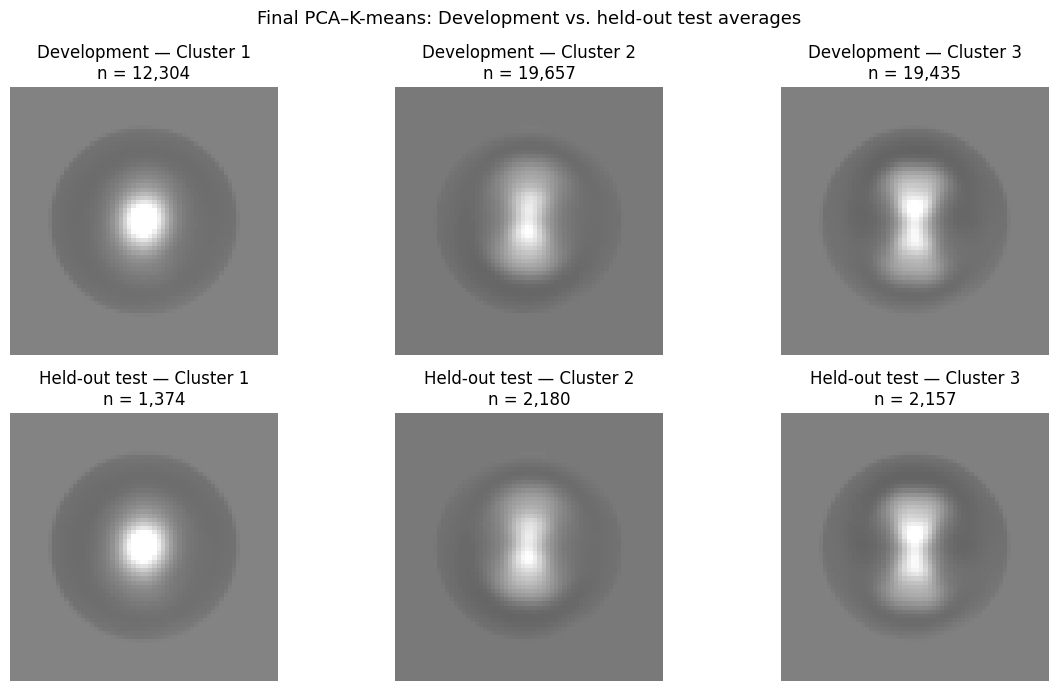

Development vs. test average comparison: COMPLETED
Held-out test particles: 5711
Test cluster counts: [1374, 2180, 2157]
Models retrained: 0
Model parameters changed: 0
Saved to: /Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48/final_development_model/heldout_test_evaluation


In [53]:
# ADDED: Compare development and held-out test cluster averages.
# Reason: Check whether the spatial patterns appear in both datasets.

development_average_path = (
    PROJECT_ROOT
    / "outputs/cluster_examples_08_final_brightness_control_48"
    / "final_cluster_average_images.npy"
)

development_averages = np.load(development_average_path)

assert development_averages.shape == (3, 64, 64)

test_average_images = []
test_cluster_counts = []

for cluster in [1, 2, 3]:

    cluster_rows = test_assignments.loc[
        test_assignments["cluster"] == cluster,
        "source_row_0based",
    ].to_numpy(dtype=int)

    assert len(cluster_rows) > 0
    assert np.isin(cluster_rows, test_idx).all()

    image_sum = np.zeros((64, 64), dtype=np.float64)

    for start in range(0, len(cluster_rows), 256):

        batch_rows = cluster_rows[start:start + 256]

        images = np.asarray(
            aligned_images[batch_rows],
            dtype=np.float64,
        )


        means = images[:, circle_mask].mean(axis=1)

        centered = images - means[:, None, None]

        image_sum += centered.sum(axis=0)

    test_average_images.append(
        image_sum / len(cluster_rows)
    )

    test_cluster_counts.append(len(cluster_rows))

test_averages = np.stack(test_average_images)

assert test_averages.shape == (3, 64, 64)
assert sum(test_cluster_counts) == 5711
assert np.isfinite(test_averages).all()

all_averages = np.concatenate(
    [development_averages, test_averages],
    axis=0,
)

shared_limit = float(
    np.percentile(
        np.abs(all_averages[:, circle_mask]),
        99,
    )
)

assert shared_limit > 0

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

development_cluster_counts = (
    verified_assignments["cluster"]
    .value_counts()
    .reindex([1, 2, 3])
)

for idx in range(3):

    axes[0, idx].imshow(
        development_averages[idx],
        cmap="gray",
        origin="lower",
        vmin=-shared_limit,
        vmax=shared_limit,
    )

    axes[0, idx].set_title(
        f"Development — Cluster {idx + 1}\n"
        f"n = {development_cluster_counts.iloc[idx]:,}"
    )

    axes[1, idx].imshow(
        test_averages[idx],
        cmap="gray",
        origin="lower",
        vmin=-shared_limit,
        vmax=shared_limit,
    )

    axes[1, idx].set_title(
        f"Held-out test — Cluster {idx + 1}\n"
        f"n = {test_cluster_counts[idx]:,}"
    )

    axes[0, idx].axis("off")
    axes[1, idx].axis("off")

fig.suptitle(
    "Final PCA–K-means: Development vs. held-out test averages",
    fontsize=13,
)

fig.tight_layout()

fig.savefig(
    test_output_dir / "development_vs_test_cluster_averages.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()
np.save(
    test_output_dir / "test_cluster_average_images.npy",
    test_averages,
)

print("Development vs. test average comparison: COMPLETED")
print("Held-out test particles:", sum(test_cluster_counts))
print("Test cluster counts:", test_cluster_counts)
print("Models retrained: 0")
print("Model parameters changed: 0")
print("Saved to:", test_output_dir)



### 9.10 Final model and held-out test conclusions

**Final exploratory model**

- Feature representation: 48 brightness-control radial features
- StandardScaler fitted on development particles only
- PCA: 5 components
- K-means: 3 clusters
- Development particles: 51,396
- Held-out test particles: 5,711

**Cross-validation**

- Mean silhouette: 0.1607
- Mean seed-stability ARI: approximately 0.962
- Cluster assignments showed very weak association with mean
  image brightness across all three folds.
- Alignment uncertainty differed across clusters.

**Held-out evaluation**

The frozen development model was applied to all 5,711 test
particles without retraining or parameter tuning.

- Test silhouette: 0.1644 (sample of 1,000 particles)
- Cluster 1: 1,374 particles (24.06%)
- Cluster 2: 2,180 particles (38.17%)
- Cluster 3: 2,157 particles (37.77%)

The held-out cluster proportions closely matched development
proportions. Corresponding cluster-average images also showed
similar spatial patterns:

- Cluster 1: compact circular central signal
- Cluster 2: vertically elongated central signal
- Cluster 3: hourglass-like central signal

**Scientific conclusion**

The unsupervised PCA–K-means pipeline identified three
reproducible groups of aligned 2D cryo-EM particle images.

These groups are not established protein conformations.
They may reflect viewing orientation, residual alignment
effects, structural heterogeneity, or other imaging factors.

The modest silhouette scores indicate considerable overlap
between the clusters.

**Limitations**

- Validation uses particle-level splits, not independent
  micrograph- or acquisition-level groups.
- Upstream CWF preprocessing may have used the full collection.
- The brightness-control representation also excludes
  positive-pixel fraction features.
- Cluster-average patterns are 2D summaries, not 3D structures.

**Final status**

PCA–K-means model development and held-out evaluation are complete.

The saved development model and test results are preserved.
No test-driven model changes were made.


In [56]:
# Inspect the frozen particle-to-fold assignments.
# No data splitting or model training is performed.

split_file = (
    PROJECT_ROOT
    / "outputs/validation/cv_3fold_with_unknown_test.csv"
)

particle_folds = pd.read_csv(split_file)

# Show how many particles belong to each fold.
print("Particles per fold:")
display(
    particle_folds["cv_fold"]
    .value_counts()
    .sort_index()
)

# Show the first 10 particle IDs from each fold.
for fold in [0, 1, 2, 3]:
    print(f"\nFold {fold} — first 10 particles")

    display(
        particle_folds.loc[
            particle_folds["cv_fold"] == fold,
            ["particle_id", "stack_index_1based", "cv_fold"]
        ].head(10)
    )

Particles per fold:


cv_fold
0     5711
1    17132
2    17132
3    17132
Name: count, dtype: int64


Fold 0 — first 10 particles


,particle_id,stack_index_1based,cv_fold
2,049671@J598/restack/batch_0_restacked.mrc,49671,0
3,049672@J598/restack/batch_0_restacked.mrc,49672,0
5,013686@J598/restack/batch_0_restacked.mrc,13686,0
20,050062@J598/restack/batch_0_restacked.mrc,50062,0
37,019710@J598/restack/batch_0_restacked.mrc,19710,0
63,052823@J598/restack/batch_0_restacked.mrc,52823,0
64,052824@J598/restack/batch_0_restacked.mrc,52824,0
66,052826@J598/restack/batch_0_restacked.mrc,52826,0
72,045410@J598/restack/batch_0_restacked.mrc,45410,0
74,045412@J598/restack/batch_0_restacked.mrc,45412,0



Fold 1 — first 10 particles


,particle_id,stack_index_1based,cv_fold
1,049670@J598/restack/batch_0_restacked.mrc,49670,1
12,041340@J598/restack/batch_0_restacked.mrc,41340,1
14,046809@J598/restack/batch_0_restacked.mrc,46809,1
22,050064@J598/restack/batch_0_restacked.mrc,50064,1
30,041586@J598/restack/batch_0_restacked.mrc,41586,1
31,041587@J598/restack/batch_0_restacked.mrc,41587,1
39,033821@J598/restack/batch_0_restacked.mrc,33821,1
48,027622@J598/restack/batch_0_restacked.mrc,27622,1
49,007236@J598/restack/batch_0_restacked.mrc,7236,1
57,018712@J598/restack/batch_0_restacked.mrc,18712,1



Fold 2 — first 10 particles


,particle_id,stack_index_1based,cv_fold
4,013685@J598/restack/batch_0_restacked.mrc,13685,2
6,041334@J598/restack/batch_0_restacked.mrc,41334,2
7,041335@J598/restack/batch_0_restacked.mrc,41335,2
8,041336@J598/restack/batch_0_restacked.mrc,41336,2
15,046810@J598/restack/batch_0_restacked.mrc,46810,2
16,046811@J598/restack/batch_0_restacked.mrc,46811,2
17,050059@J598/restack/batch_0_restacked.mrc,50059,2
21,050063@J598/restack/batch_0_restacked.mrc,50063,2
24,034214@J598/restack/batch_0_restacked.mrc,34214,2
25,034215@J598/restack/batch_0_restacked.mrc,34215,2



Fold 3 — first 10 particles


,particle_id,stack_index_1based,cv_fold
0,049669@J598/restack/batch_0_restacked.mrc,49669,3
9,041337@J598/restack/batch_0_restacked.mrc,41337,3
10,041338@J598/restack/batch_0_restacked.mrc,41338,3
11,041339@J598/restack/batch_0_restacked.mrc,41339,3
13,041341@J598/restack/batch_0_restacked.mrc,41341,3
18,050060@J598/restack/batch_0_restacked.mrc,50060,3
19,050061@J598/restack/batch_0_restacked.mrc,50061,3
23,034213@J598/restack/batch_0_restacked.mrc,34213,3
26,034216@J598/restack/batch_0_restacked.mrc,34216,3
27,034217@J598/restack/batch_0_restacked.mrc,34217,3



### 9.11 Exploratory hyperparameter search — 48 brightness-control features

**Objective**

Investigate whether different PCA dimensions and K-means cluster
numbers provide better clustering characteristics for the
48-feature brightness-control representation.

**Parameters**

- PCA components: 5, 10, 15
- K-means clusters: 3, 4, 5, 6, 8
- Cross-validation: 3 frozen development folds

**Method**

For each parameter combination:

1. Fit StandardScaler on the training folds.
2. Fit PCA on the standardized training data.
3. Fit K-means on the training PCA coordinates.
4. Predict cluster assignments for the validation fold.
5. Calculate validation silhouette scores.
6. Compare results across all three folds.

**Data restrictions**

- Use only the 51,396 development particles.
- Do not use the 5,711 held-out test particles.
- Preserve the previously fitted final model and all saved results.

**Important**

This is a post-test exploratory experiment because the original
held-out test results have already been examined.

Any newly selected configuration requires independent new data
for a fresh, unbiased final evaluation.


In [57]:

# Exploratory grid search using 48 brightness-control features.
# Reason: Compare PCA dimensions and K-means cluster counts (Done after training)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

# Hyperparameters to investigate.
GRID_PCA_COMPONENTS = (5, 10, 15)
GRID_K_VALUES = (3, 4, 5, 6, 8)
GRID_RANDOM_STATE = 0
GRID_SILHOUETTE_SAMPLE = 1000

grid_dir = offset_dir / "post_test_grid_search_48"
grid_dir.mkdir(parents=True, exist_ok=True)

assert X_offset_control.shape == (51396, 48)
assert len(development_rows) == 51396
assert np.isfinite(X_offset_control).all()
assert not np.isin(development_rows, test_idx).any()

grid_folds = (
    manifest["cv_fold"]
    .to_numpy(dtype=int)[development_rows]
)

assert set(np.unique(grid_folds)) == {1, 2, 3}

grid_records = []

with threadpool_limits(limits=THREADS):

    for fold in [1, 2, 3]:

        train_idx_local = np.flatnonzero(grid_folds != fold)
        val_idx_local = np.flatnonzero(grid_folds == fold)

        assert len(train_idx_local) == 34264
        assert len(val_idx_local) == 17132

        X_train = X_offset_control[train_idx_local]
        X_val = X_offset_control[val_idx_local]

        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)

        rng = np.random.default_rng(SPLIT_SEED)

        sample_idx = rng.choice(
            len(X_val_scaled),
            size=GRID_SILHOUETTE_SAMPLE,
            replace=False,
        )

        for n_pcs in GRID_PCA_COMPONENTS:

            # Fit PCA on training particles only.
            pca = PCA(
                n_components=n_pcs,
                svd_solver="randomized",
                random_state=SPLIT_SEED,
            )

            Z_train = pca.fit_transform(X_train_scaled)
            Z_val = pca.transform(X_val_scaled)

            explained_variance = float(
                pca.explained_variance_ratio_.sum()
            )

            for k in GRID_K_VALUES:

                # Fit K-means on training PCA coordinates.
                kmeans = KMeans(
                    n_clusters=k,
                    random_state=GRID_RANDOM_STATE,
                    n_init=20,
                )

                kmeans.fit(Z_train)

                # Predict clusters on unseen validation particles.
                val_labels = kmeans.predict(Z_val)

                # Evaluate the same 1,000 validation # particles for each configuration in this fold.
                sample_labels = val_labels[sample_idx]

                n_sample_clusters = len(
                    np.unique(sample_labels)
                )

                if 2 <= n_sample_clusters < len(sample_labels):
                    silhouette = float(
                        silhouette_score(
                            Z_val[sample_idx],
                            sample_labels,
                        )
                    )
                else:
                    silhouette = float("nan")

                cluster_sizes = np.bincount(
                    val_labels,
                    minlength=k,
                )

                min_cluster_pct = float(
                    100 * cluster_sizes.min() / len(val_labels)
                )

                grid_records.append({
                    "fold": fold,
                    "n_pcs": n_pcs,
                    "k": k,
                    "n_train": len(train_idx_local),
                    "n_validation": len(val_idx_local),
                    "explained_variance": explained_variance,
                    "silhouette": silhouette,
                    "min_cluster_pct": min_cluster_pct,
                })

        print(f"Fold {fold}: completed 15 configurations")

grid_results_48 = pd.DataFrame(grid_records)

assert len(grid_results_48) == 45
assert grid_results_48["silhouette"].notna().all()
assert grid_results_48.groupby(
    ["n_pcs", "k"]
).size().eq(3).all()

Summarize validation results across the three folds.
grid_summary_48 = (
    grid_results_48
    .groupby(["n_pcs", "k"], as_index=False)
    .agg(
        mean_silhouette=("silhouette", "mean"),
        std_silhouette=("silhouette", "std"),
        mean_explained_variance=("explained_variance", "mean"),
        mean_min_cluster_pct=("min_cluster_pct", "mean"),
    )
    .sort_values(
        "mean_silhouette",
        ascending=False,
    )
    .reset_index(drop=True)
)

grid_results_48.to_csv(
    grid_dir / "grid_results_by_fold.csv",
    index=False,
)

grid_summary_48.to_csv(
    grid_dir / "grid_summary.csv",
    index=False,
)

print("\n48-FEATURE GRID SEARCH: COMPLETED")
print("PCA settings:", GRID_PCA_COMPONENTS)
print("K-means settings:", GRID_K_VALUES)
print("Validation folds:", 3)
print("Total evaluations:", len(grid_results_48))
print("Held-out test particles used: 0")
print("Existing final model modified: NO")

print("\nConfigurations ranked by mean validation silhouette:")
display(grid_summary_48.round(4))

print("\nHighest silhouette among tested configurations:")
display(grid_summary_48.head(1).round(4))

print("\nResults saved to:")
print(grid_dir)


Fold 1: completed 15 configurations
Fold 2: completed 15 configurations
Fold 3: completed 15 configurations

48-FEATURE GRID SEARCH: COMPLETED
PCA settings: (5, 10, 15)
K-means settings: (3, 4, 5, 6, 8)
Validation folds: 3
Total evaluations: 45
Held-out test particles used: 0
Existing final model modified: NO

Configurations ranked by mean validation silhouette:


,n_pcs,k,mean_silhouette,std_silhouette,mean_explained_variance,mean_min_cluster_pct
0,5,3,0.1611,0.0040,0.5264,23.9513
1,5,4,0.1593,0.0049,0.5264,18.7408
2,5,5,0.1498,0.0058,0.5264,16.1550
3,5,6,0.1457,0.0086,0.5264,13.7287
4,5,8,0.1354,0.0108,0.5264,10.2518
5,10,3,0.1116,0.0049,0.7157,23.2898
6,10,4,0.1084,0.0054,0.7157,17.7815
7,10,6,0.0990,0.0083,0.7157,12.3628
8,10,5,0.0986,0.0052,0.7157,13.2092
9,15,3,0.0980,0.0033,0.8060,23.5116



Highest silhouette among tested configurations:


,n_pcs,k,mean_silhouette,std_silhouette,mean_explained_variance,mean_min_cluster_pct
0,5,3,0.1611,0.004,0.5264,23.9513



Results saved to:
/Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48/post_test_grid_search_48



#### 9.11.1 Exploratory grid-search results

We performed a post-test exploratory hyperparameter comparison
using the 48-feature brightness-control representation.

**Experimental design**
- PCA components: 5, 10, 15
- K-means clusters: 3, 4, 5, 6, 8
- Three frozen development folds
- 15 parameter combinations, evaluated across three folds
- Held-out test particles excluded

**Results**
- Highest mean validation silhouette: 0.1611
- Leading configuration: 5 PCA components, K = 3
- Standard deviation across folds: 0.0040
- PCA explained variance: 52.64%
- Smallest cluster: approximately 23.95% on average

The K = 4 configuration with 5 PCA components produced a
similar silhouette (0.1593). Thus, the results support
5 PCs and K = 3 as a reasonable configuration among those
tested, but do not establish that it is uniquely optimal.

Adding PCA components increased explained variance but reduced
silhouette scores in the tested configurations.

**Scientific interpretation**

The results support the previously selected exploratory
configuration. However, silhouette separation remains modest,
and the clusters cannot yet be interpreted as distinct protein
conformations.

**Data-leakage and evaluation limitations**

This grid search was performed after inspecting the original
held-out test results.

It used development folds only and did not modify the saved
final model. It is reported as exploratory follow-up analysis,
not as part of the original pre-test model selection.

No new independent held-out evaluation was conducted.
```


Plot table:


n_pcs,5,10,15
k,,,
3,0.161070,0.111591,0.097970
4,0.159268,0.108375,0.094070
5,0.149784,0.098573,0.084348
6,0.145659,0.099007,0.084482
8,0.135366,0.089563,0.075834


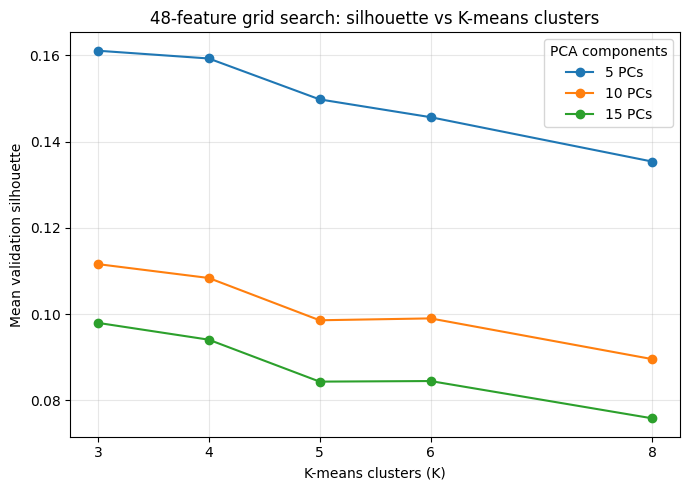

Saved figure to:
/Users/kr/ml4ls/outputs/validation_09/20261109T175733Z/parameter_comparison/candidate_5pcs_k3/brightness_control_48/post_test_grid_search_48/grid_search_silhouette_by_k.png


In [58]:
# ADDED: Plot grid-search results with K-means K on the x-axis.


import matplotlib.pyplot as plt
import pandas as pd

assert "grid_summary_48" in globals(), "Run the 48-feature grid search cell first."

# Pivot table for plotting:
# rows = K values
# columns = PCA component counts
# values = mean silhouette
plot_table = grid_summary_48.pivot(
    index="k",
    columns="n_pcs",
    values="mean_silhouette"
).sort_index()

print("Plot table:")
display(plot_table)

fig, ax = plt.subplots(figsize=(7, 5))

for n_pcs in plot_table.columns:
    ax.plot(
        plot_table.index,
        plot_table[n_pcs],
        marker="o",
        label=f"{n_pcs} PCs"
    )

ax.set_title("48-feature grid search: silhouette vs K-means clusters")
ax.set_xlabel("K-means clusters (K)")
ax.set_ylabel("Mean validation silhouette")
ax.set_xticks(plot_table.index)
ax.legend(title="PCA components")
ax.grid(True, alpha=0.3)

fig.tight_layout()

# Optional: save figure
save_path = grid_dir / "grid_search_silhouette_by_k.png"
fig.savefig(save_path, dpi=160)

plt.show()

print("Saved figure to:")
print(save_path)